# Aquaculture Yield Prediction

## Problem Statement
### To analyze the factors affecting aquaculture yield and develop a Linear Regression model to predict production based on relevant environmental and operational variables.

#### **Goal:** predict the **harvest per acre (kg)** of an aquaculture pond from its stocking density, feed, water-quality readings (dissolved oxygen, pH, ammonia, temperature), aeration, and farm practices, and identify which factors move yield the most.


## Objectives:
- Perform EDA and data cleaning.
- Analyze correlations between features and yield.
- Handle missing values, outliers, and categorical variables.
- Build and evaluate Linear Regression using appropriate metrics.
- Check multicollinearity (VIF) and residual assumptions.
- Compare Linear Regression with Ridge, Lasso, and Elastic Net.

### Dataset overview
The dataset contains **2302 rows** and **22 columns**. Target variable: **harvest_kg_per_acre**.

### Importing Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
import pandas as pd

### Load the dataset

In [2]:
df = pd.read_csv(r"C:\Users\tanis\aquaculture_yield.csv")

In [3]:
df

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
0,PND11915,Odisha,Pangasius,Freshwater,1.93,1.1,10,9000.0,6.4,165.0,...,6.0,27.9,8.1,8.0,0.21,10.0,Yes,No,27.0,4413.0
1,PND10924,Odisha,Pangasius,Freshwater,3.31,1.3,5,8800.0,6.8,168.0,...,8.0,28.8,6.1,7.5,0.53,5.0,No,Yes,22.0,7536.0
2,PND10873,Assam,Tilapia,Freshwater,0.59,0.9,19,5400.0,5.7,203.0,...,1.0,27.2,6.5,8.1,0.49,12.0,No,Yes,29.0,3116.0
3,PND10410,Andhra Pradesh,Tilapia,Freshwater,0.44,1.8,18,9400.0,4.3,178.0,...,1.0,30.3,4.8,8.0,0.41,13.0,No,No,18.0,5646.0
4,PND10369,Kerala,Rohu,Freshwater,4.15,1.3,11,5700.0,7.2,203.0,...,6.0,29.7,5.4,7.8,0.37,22.0,Yes,Yes,27.0,2243.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2297,PND11697,Andhra Pradesh,Catla,Freshwater,1.07,1.9,6,8900.0,10.2,202.0,...,2.0,31.2,6.3,7.6,0.28,24.0,No,Yes,13.0,4647.0
2298,PND10300,Andhra Pradesh,Catla,Freshwater,1.85,1.9,17,4500.0,7.8,185.0,...,3.0,28.6,4.3,7.3,0.26,25.0,No,No,4.0,2101.0
2299,PND10042,Odisha,Rohu,Freshwater,1.39,1.7,7,8500.0,5.8,194.0,...,2.0,32.8,6.8,7.6,0.32,NaN,No,Yes,16.0,4228.0
2300,PND11071,Bihar,Rohu,Freshwater,1.11,1.7,1,5500.0,4.4,192.0,...,3.0,35.3,6.7,6.3,0.38,3.0,No,No,13.0,1941.0


### Initial Dataset Overview

### Before any cleaning, let's look at the raw shape, structure, and a preview of the data.

In [4]:
df.head()     # displays the top 5 rows

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
0,PND11915,Odisha,Pangasius,Freshwater,1.93,1.1,10,9000.0,6.4,165.0,...,6.0,27.9,8.1,8.0,0.21,10.0,Yes,No,27.0,4413.0
1,PND10924,Odisha,Pangasius,Freshwater,3.31,1.3,5,8800.0,6.8,168.0,...,8.0,28.8,6.1,7.5,0.53,5.0,No,Yes,22.0,7536.0
2,PND10873,Assam,Tilapia,Freshwater,0.59,0.9,19,5400.0,5.7,203.0,...,1.0,27.2,6.5,8.1,0.49,12.0,No,Yes,29.0,3116.0
3,PND10410,Andhra Pradesh,Tilapia,Freshwater,0.44,1.8,18,9400.0,4.3,178.0,...,1.0,30.3,4.8,8.0,0.41,13.0,No,No,18.0,5646.0
4,PND10369,Kerala,Rohu,Freshwater,4.15,1.3,11,5700.0,7.2,203.0,...,6.0,29.7,5.4,7.8,0.37,22.0,Yes,Yes,27.0,2243.0


In [5]:
df.tail()     # displays the last 5 rows

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
2297,PND11697,Andhra Pradesh,Catla,Freshwater,1.07,1.9,6,8900.0,10.2,202.0,...,2.0,31.2,6.3,7.6,0.28,24.0,No,Yes,13.0,4647.0
2298,PND10300,Andhra Pradesh,Catla,Freshwater,1.85,1.9,17,4500.0,7.8,185.0,...,3.0,28.6,4.3,7.3,0.26,25.0,No,No,4.0,2101.0
2299,PND10042,Odisha,Rohu,Freshwater,1.39,1.7,7,8500.0,5.8,194.0,...,2.0,32.8,6.8,7.6,0.32,NaN,No,Yes,16.0,4228.0
2300,PND11071,Bihar,Rohu,Freshwater,1.11,1.7,1,5500.0,4.4,192.0,...,3.0,35.3,6.7,6.3,0.38,3.0,No,No,13.0,1941.0
2301,PND11945,Andhra Pradesh,Tilapia,Freshwater,0.87,1.8,2,3600.0,6.0,217.0,...,0.0,27.3,5.4,7.6,0.42,NaN,Yes,Yes,10.0,1757.0


In [6]:
df.shape    #(rows,columns)

(2302, 22)

In [7]:
df.describe()

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,farmer_experience_yrs,harvest_kg_per_acre
count,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2239.000000,2302.000000,2233.000000,2255.000000,2302.000000,2302.000000
mean,1.759805,1.603215,12.105560,7166.246742,5.969548,192.263249,4581.507385,2.787576,28.521438,5.447566,7.792572,0.418451,11.845676,15.018679,3302.245439
std,1.109500,0.353757,7.180341,2578.816469,2.632605,39.591155,1887.474250,2.763857,2.688172,1.126273,0.446057,0.170080,6.432583,7.627981,1486.672815
min,0.200000,0.800000,0.000000,1500.000000,1.000000,90.000000,500.000000,0.000000,18.400000,1.800000,6.300000,0.070000,0.000000,1.000000,200.000000
25%,0.980000,1.400000,6.000000,5500.000000,4.200000,166.000000,3375.000000,1.000000,26.800000,4.800000,7.500000,0.320000,8.000000,9.000000,2269.500000
50%,1.490000,1.600000,12.000000,7100.000000,6.000000,192.000000,4445.000000,2.000000,28.500000,5.400000,7.800000,0.390000,12.000000,15.000000,3063.500000
75%,2.277500,1.800000,18.000000,8800.000000,7.700000,219.000000,5556.000000,4.000000,30.200000,6.200000,8.100000,0.490000,16.000000,21.000000,3978.750000
max,12.520000,2.600000,24.000000,16700.000000,14.200000,317.000000,13468.000000,30.000000,36.000000,9.100000,9.400000,1.390000,35.000000,29.000000,12729.000000


In [8]:
df.describe(include='all')

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
count,2302,2302,2302,2302,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,2302.000000,...,2302.000000,2302.000000,2239.000000,2302.000000,2233.000000,2255.000000,2302,2302,2302.000000,2302.000000
unique,2300,8,6,2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2,2,NaN,NaN
top,PND10745,Andhra Pradesh,Rohu,Freshwater,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,No,Yes,NaN,NaN
freq,2,682,563,1959,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1907,1181,NaN,NaN
mean,NaN,NaN,NaN,NaN,1.759805,1.603215,12.105560,7166.246742,5.969548,192.263249,...,2.787576,28.521438,5.447566,7.792572,0.418451,11.845676,NaN,NaN,15.018679,3302.245439
std,NaN,NaN,NaN,NaN,1.109500,0.353757,7.180341,2578.816469,2.632605,39.591155,...,2.763857,2.688172,1.126273,0.446057,0.170080,6.432583,NaN,NaN,7.627981,1486.672815
min,NaN,NaN,NaN,NaN,0.200000,0.800000,0.000000,1500.000000,1.000000,90.000000,...,0.000000,18.400000,1.800000,6.300000,0.070000,0.000000,NaN,NaN,1.000000,200.000000
25%,NaN,NaN,NaN,NaN,0.980000,1.400000,6.000000,5500.000000,4.200000,166.000000,...,1.000000,26.800000,4.800000,7.500000,0.320000,8.000000,NaN,NaN,9.000000,2269.500000
50%,NaN,NaN,NaN,NaN,1.490000,1.600000,12.000000,7100.000000,6.000000,192.000000,...,2.000000,28.500000,5.400000,7.800000,0.390000,12.000000,NaN,NaN,15.000000,3063.500000
75%,NaN,NaN,NaN,NaN,2.277500,1.800000,18.000000,8800.000000,7.700000,219.000000,...,4.000000,30.200000,6.200000,8.100000,0.490000,16.000000,NaN,NaN,21.000000,3978.750000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2302 entries, 0 to 2301
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   pond_id                      2302 non-null   object 
 1   state                        2302 non-null   object 
 2   species                      2302 non-null   object 
 3   water_type                   2302 non-null   object 
 4   pond_area_acres              2302 non-null   float64
 5   avg_depth_m                  2302 non-null   float64
 6   pond_age_yrs                 2302 non-null   int64  
 7   stocking_density_per_acre    2302 non-null   float64
 8   seed_size_g                  2302 non-null   float64
 9   culture_days                 2302 non-null   float64
 10  total_feed_kg_per_acre       2302 non-null   float64
 11  feed_type                    2302 non-null   object 
 12  aerators_installed           2302 non-null   float64
 13  avg_water_temp_c  

### Checking for the null values

#### Before any modeling, we check whether any columns contain missing values and how large the missing percentage is. This helps us decide an appropriate handling strategy (mean/mode/random sampling, etc.).

In [10]:
df.isnull().sum()

pond_id                         0
state                           0
species                         0
water_type                      0
pond_area_acres                 0
avg_depth_m                     0
pond_age_yrs                    0
stocking_density_per_acre       0
seed_size_g                     0
culture_days                    0
total_feed_kg_per_acre          0
feed_type                       0
aerators_installed              0
avg_water_temp_c                0
dissolved_oxygen_mg_l          63
ph                              0
ammonia_mg_l                   69
water_exchange_pct_per_week    47
disease_outbreak                0
probiotic_use                   0
farmer_experience_yrs           0
harvest_kg_per_acre             0
dtype: int64

In [11]:
(df.isnull().sum()/len(df)*100).sort_values(ascending=False)

ammonia_mg_l                   2.997394
dissolved_oxygen_mg_l          2.736751
water_exchange_pct_per_week    2.041703
pond_id                        0.000000
state                          0.000000
farmer_experience_yrs          0.000000
probiotic_use                  0.000000
disease_outbreak               0.000000
ph                             0.000000
avg_water_temp_c               0.000000
aerators_installed             0.000000
feed_type                      0.000000
total_feed_kg_per_acre         0.000000
culture_days                   0.000000
seed_size_g                    0.000000
stocking_density_per_acre      0.000000
pond_age_yrs                   0.000000
avg_depth_m                    0.000000
pond_area_acres                0.000000
water_type                     0.000000
species                        0.000000
harvest_kg_per_acre            0.000000
dtype: float64

- Only 3 columns have missing values: ammonia_mg_l, dissolved_oxygen_mg_l and water_exchange_pct_per_week.
- Each of them has roughly 2–3% missing, which is small enough to fill instead of dropping rows.

### Checking for Duplicate Rows

In [12]:
df.duplicated().sum()

np.int64(2)

In [13]:
df[df.duplicated(keep=False)]

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
253,PND11014,Andhra Pradesh,Vannamei Shrimp,Brackish,0.85,1.6,19,6400.0,8.8,148.0,...,0.0,28.6,4.7,7.8,0.60,13.0,No,No,10.0,2268.0
400,PND11014,Andhra Pradesh,Vannamei Shrimp,Brackish,0.85,1.6,19,6400.0,8.8,148.0,...,0.0,28.6,4.7,7.8,0.60,13.0,No,No,10.0,2268.0
864,PND10745,Kerala,Vannamei Shrimp,Brackish,1.89,1.2,10,8400.0,3.1,213.0,...,4.0,28.5,5.9,7.8,0.38,NaN,No,Yes,17.0,3810.0
2257,PND10745,Kerala,Vannamei Shrimp,Brackish,1.89,1.2,10,8400.0,3.1,213.0,...,4.0,28.5,5.9,7.8,0.38,NaN,No,Yes,17.0,3810.0


- There are 2 duplicate rows - each pond appears twice with identical values in every column.

### Handling Duplicates

In [14]:
df = df.drop_duplicates().reset_index(drop=True)    # drop the duplicate rows

In [15]:
df.duplicated().sum()      # check if the duplicates are removed

np.int64(0)

### Check the datatype of each column

In [16]:
df.dtypes

pond_id                         object
state                           object
species                         object
water_type                      object
pond_area_acres                float64
avg_depth_m                    float64
pond_age_yrs                     int64
stocking_density_per_acre      float64
seed_size_g                    float64
culture_days                   float64
total_feed_kg_per_acre         float64
feed_type                       object
aerators_installed             float64
avg_water_temp_c               float64
dissolved_oxygen_mg_l          float64
ph                             float64
ammonia_mg_l                   float64
water_exchange_pct_per_week    float64
disease_outbreak                object
probiotic_use                   object
farmer_experience_yrs          float64
harvest_kg_per_acre            float64
dtype: object

### Handle missing values

- ammonia_mg_l and dissolved_oxygen_mg_l are continuous numeric columns, so they are filled using the mean.
- water_exchange_pct_per_week is a discrete numeric column, so it is filled using random sampling based on the existing value distribution. This keeps realistic values.

In [17]:
df['ammonia_mg_l'].describe()

count    2231.000000
mean        0.418386
std         0.170111
min         0.070000
25%         0.320000
50%         0.390000
75%         0.485000
max         1.390000
Name: ammonia_mg_l, dtype: float64

In [18]:
df['dissolved_oxygen_mg_l'].describe()

count    2237.000000
mean        5.447698
std         1.126625
min         1.800000
25%         4.800000
50%         5.400000
75%         6.200000
max         9.100000
Name: dissolved_oxygen_mg_l, dtype: float64

In [19]:
df['water_exchange_pct_per_week'].value_counts().sort_index()

water_exchange_pct_per_week
0.0     115
1.0      35
2.0      49
3.0      68
4.0      78
5.0      65
6.0      72
7.0      60
8.0      93
9.0      83
10.0    100
11.0    216
12.0    266
13.0    150
14.0    123
15.0    104
16.0     94
17.0     68
18.0     77
19.0     66
20.0     59
21.0     58
22.0     37
23.0     21
24.0     21
25.0     16
26.0     18
27.0     16
28.0      4
29.0     10
30.0      4
31.0      4
33.0      1
34.0      1
35.0      2
Name: count, dtype: int64

In [20]:
cols = ['ammonia_mg_l','dissolved_oxygen_mg_l']
for i in cols:
    df[i] = df[i].fillna(df[i].mean())

In [21]:
df.isnull().sum()

pond_id                         0
state                           0
species                         0
water_type                      0
pond_area_acres                 0
avg_depth_m                     0
pond_age_yrs                    0
stocking_density_per_acre       0
seed_size_g                     0
culture_days                    0
total_feed_kg_per_acre          0
feed_type                       0
aerators_installed              0
avg_water_temp_c                0
dissolved_oxygen_mg_l           0
ph                              0
ammonia_mg_l                    0
water_exchange_pct_per_week    46
disease_outbreak                0
probiotic_use                   0
farmer_experience_yrs           0
harvest_kg_per_acre             0
dtype: int64

In [22]:
water_exch = df['water_exchange_pct_per_week'].value_counts(normalize=True)
print(water_exch.head())
water_exch_nullval_index = df[df['water_exchange_pct_per_week'].isnull()].index
print(len(water_exch_nullval_index))

water_exchange_pct_per_week
12.0    0.118012
11.0    0.095830
13.0    0.066548
14.0    0.054570
0.0     0.051020
Name: proportion, dtype: float64
46


In [23]:
np.random.seed(57)
water_exch_fill_val = np.random.choice(water_exch.index,size=len(water_exch_nullval_index), p=water_exch.values)
water_exch_fill_val

array([12., 13., 15., 14.,  9.,  8.,  5., 22.,  8., 15., 12.,  2., 15.,
        9., 13., 10., 10., 12., 22., 11., 21., 12., 29., 12., 15., 12.,
       12., 17., 12., 12., 12., 14., 15., 12., 10.,  6.,  6.,  5., 12.,
        2.,  5., 18., 20.,  8., 11.,  8.])

In [24]:
df.loc[water_exch_nullval_index,'water_exchange_pct_per_week'] = water_exch_fill_val

In [25]:
df.loc[water_exch_nullval_index,'water_exchange_pct_per_week']

32      12.0
37      13.0
125     15.0
188     14.0
225      9.0
287      8.0
293      5.0
339     22.0
354      8.0
407     15.0
500     12.0
519      2.0
693     15.0
780      9.0
839     13.0
863     10.0
918     10.0
991     12.0
1001    22.0
1002    11.0
1020    21.0
1029    12.0
1070    29.0
1117    12.0
1129    15.0
1150    12.0
1160    12.0
1165    17.0
1252    12.0
1271    12.0
1325    12.0
1385    14.0
1433    15.0
1498    12.0
1523    10.0
1768     6.0
1775     6.0
1776     5.0
1800    12.0
1986     2.0
2008     5.0
2030    18.0
2061    20.0
2143     8.0
2297    11.0
2299     8.0
Name: water_exchange_pct_per_week, dtype: float64

In [26]:
df.isnull().sum().sum()   # total nulls left in the dataset

np.int64(0)

In [27]:
df.describe()

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,farmer_experience_yrs,harvest_kg_per_acre
count,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000,2300.000000
mean,1.760143,1.603391,12.103478,7166.043478,5.969565,192.273478,4581.295217,2.788261,28.521413,5.447698,7.792565,0.418386,11.849565,15.020000,3302.474348
std,1.109817,0.353811,7.181890,2579.760113,2.632408,39.595250,1887.858050,2.764332,2.689341,1.111082,0.446251,0.167539,6.412388,7.630468,1487.125192
min,0.200000,0.800000,0.000000,1500.000000,1.000000,90.000000,500.000000,0.000000,18.400000,1.800000,6.300000,0.070000,0.000000,1.000000,200.000000
25%,0.980000,1.400000,6.000000,5500.000000,4.200000,166.000000,3374.500000,1.000000,26.800000,4.800000,7.500000,0.320000,8.000000,9.000000,2270.500000
50%,1.490000,1.600000,12.000000,7100.000000,6.000000,192.000000,4445.000000,2.000000,28.500000,5.447698,7.800000,0.390000,12.000000,15.000000,3063.500000
75%,2.280000,1.800000,18.000000,8800.000000,7.700000,219.000000,5556.000000,4.000000,30.200000,6.100000,8.100000,0.480000,16.000000,21.000000,3981.500000
max,12.520000,2.600000,24.000000,16700.000000,14.200000,317.000000,13468.000000,30.000000,36.000000,9.100000,9.400000,1.390000,35.000000,29.000000,12729.000000


### Save a cleaned copy


In [28]:
df.to_csv("cleaned_data_aquaculture_yield.csv",index=False)

## Exploratory Data Analysis (EDA)


In [29]:
cat_cols = df.select_dtypes(exclude='number').columns.drop('pond_id')
num_cols = df.select_dtypes(include='number').columns
print(cat_cols)
print(num_cols)

Index(['state', 'species', 'water_type', 'feed_type', 'disease_outbreak',
       'probiotic_use'],
      dtype='object')
Index(['pond_area_acres', 'avg_depth_m', 'pond_age_yrs',
       'stocking_density_per_acre', 'seed_size_g', 'culture_days',
       'total_feed_kg_per_acre', 'aerators_installed', 'avg_water_temp_c',
       'dissolved_oxygen_mg_l', 'ph', 'ammonia_mg_l',
       'water_exchange_pct_per_week', 'farmer_experience_yrs',
       'harvest_kg_per_acre'],
      dtype='object')


###  Univariate analysis (categorical)

#### 1) Univariate Analysis- Countplot

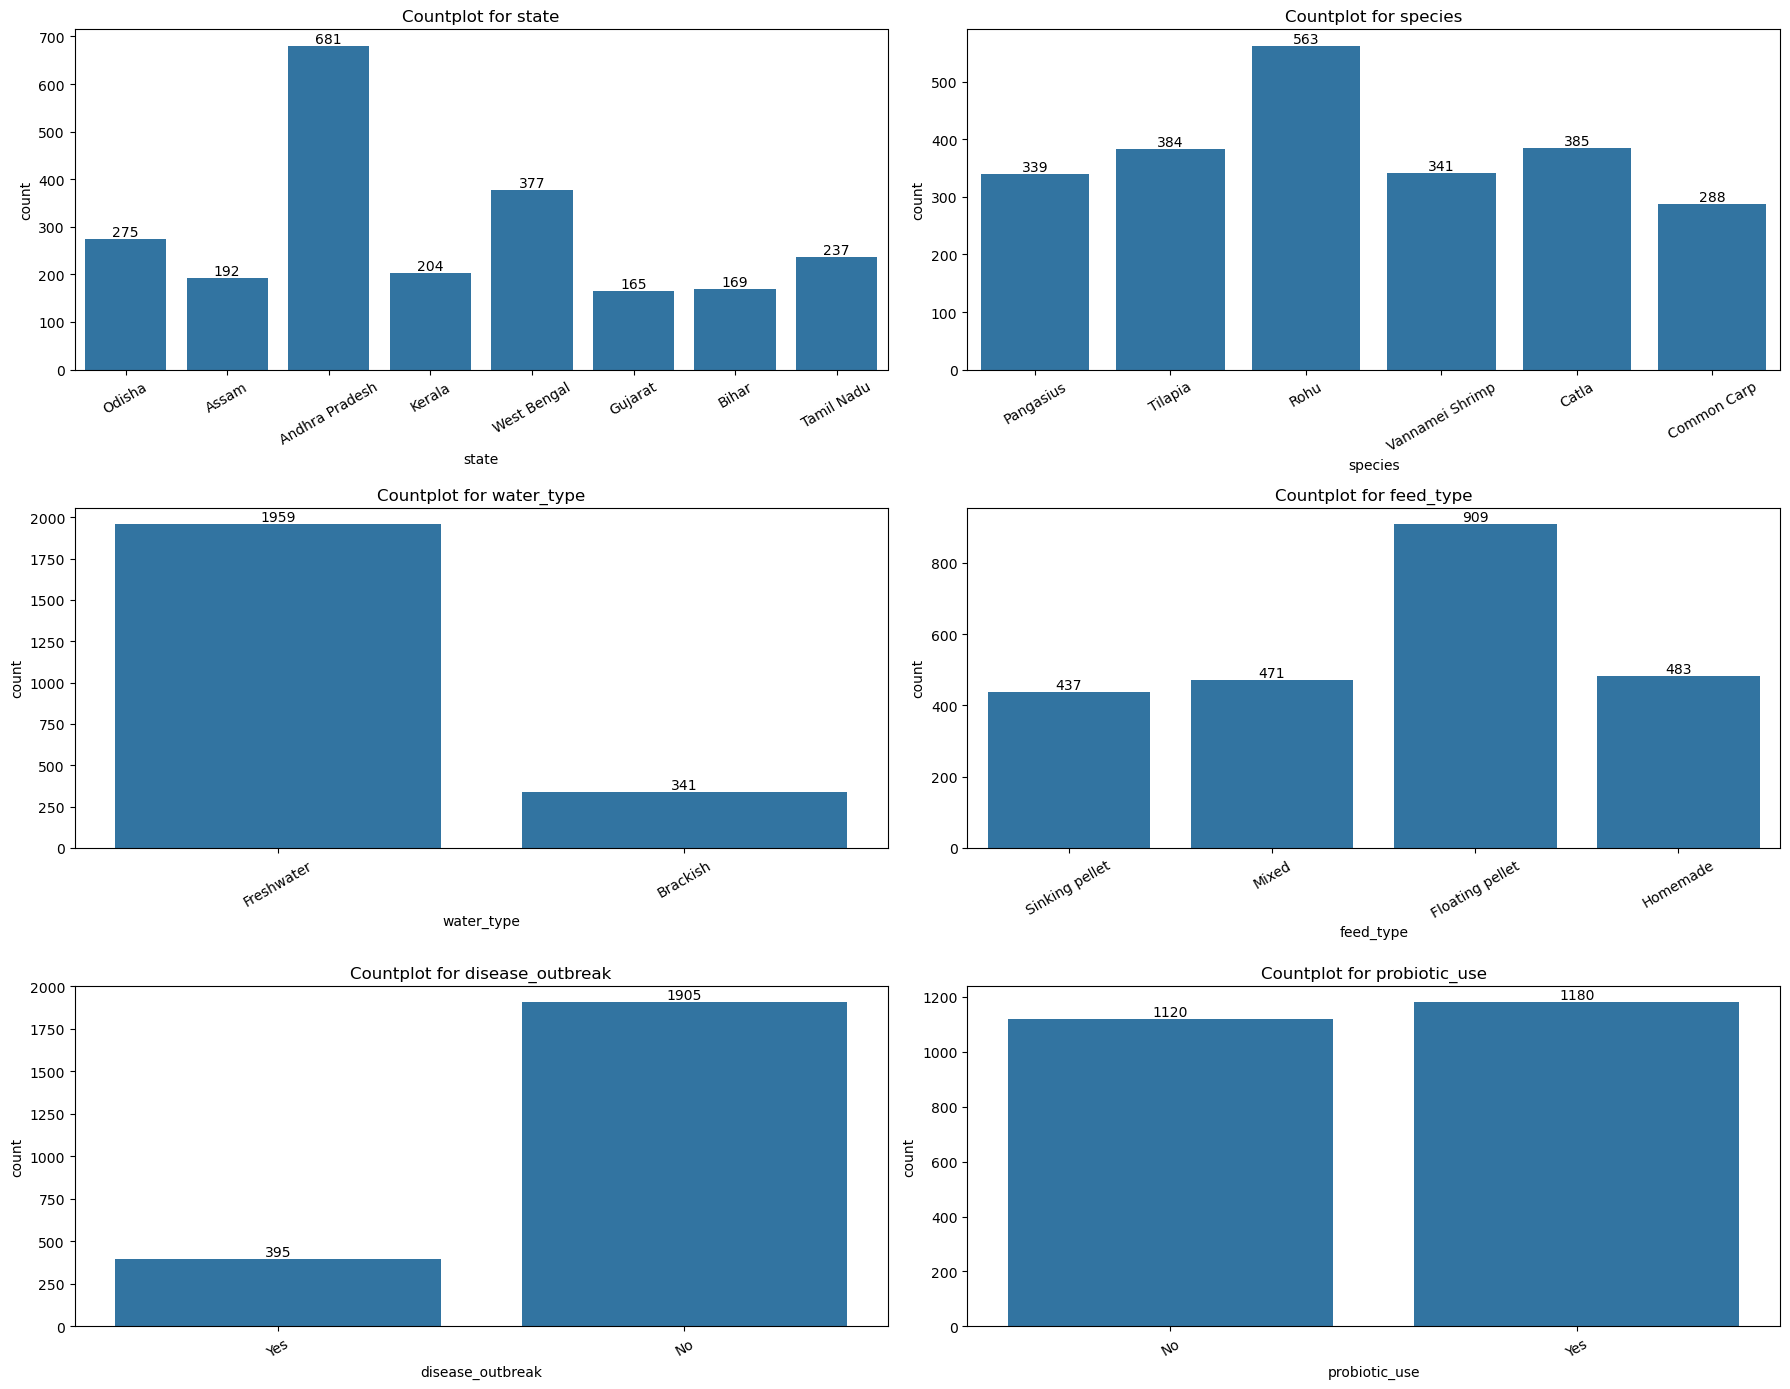

In [30]:
cols = cat_cols

plt.figure(figsize=(18, 14))

for i in range(len(cols)):
    plt.subplot((len(cols) + 1) // 2, 2, i + 1)
    ax = sns.countplot(x=df[cols[i]])
    ax.bar_label(ax.containers[0])
    plt.xticks(rotation=30)
    plt.title(f'Countplot for {cols[i]}')

plt.tight_layout()
plt.show()

#### 2) Univariate Analysis- PieChart

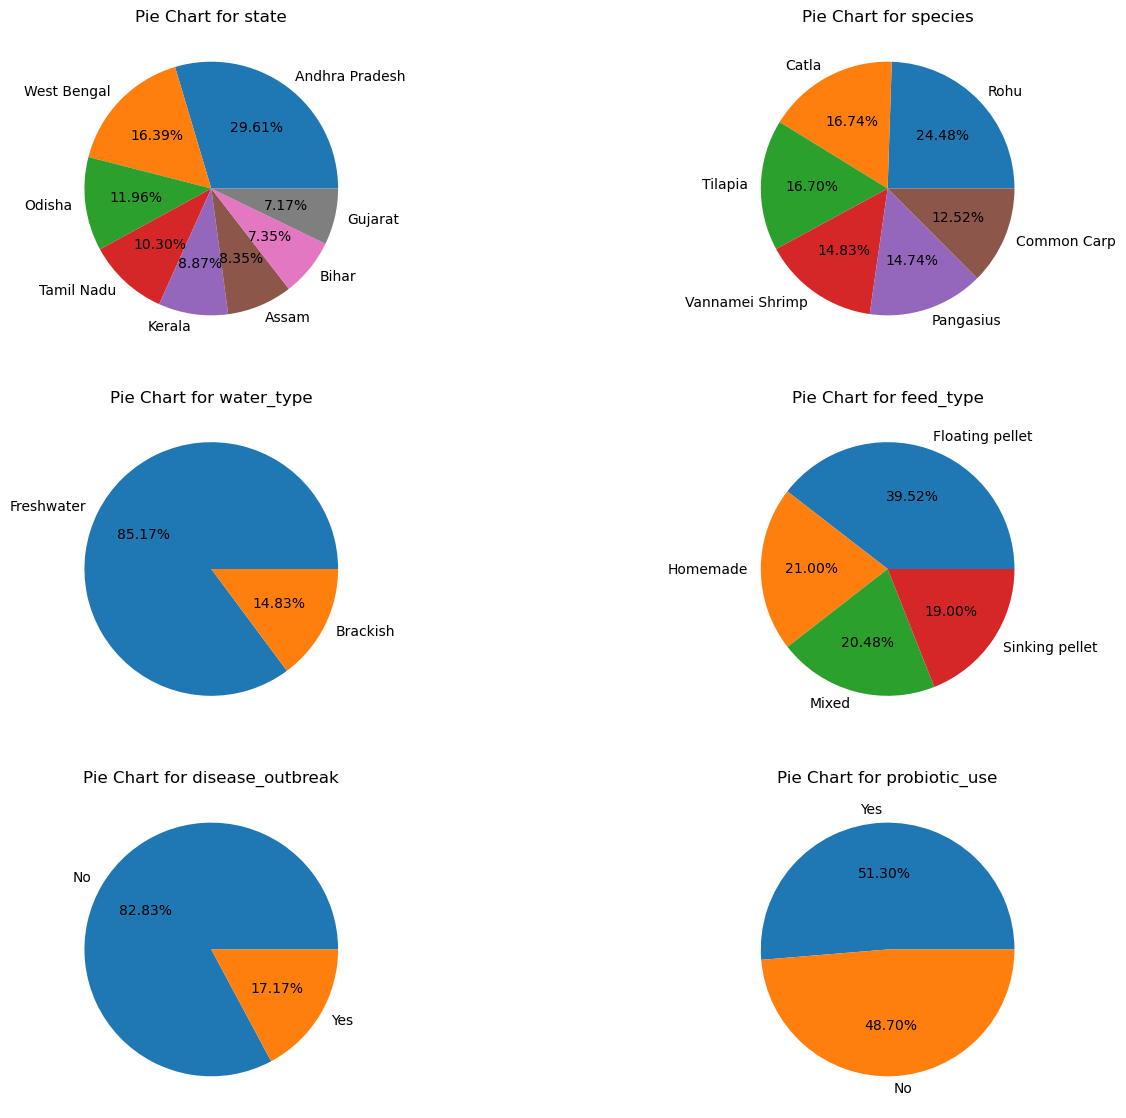

In [31]:
cols = cat_cols

plt.figure(figsize=(16,14))
for i in range(len(cols)):
    plt.subplot(3,2,i+1)
    x = df[cols[i]].value_counts()
    plt.pie(x.values,labels=x.index,autopct='%.2f%%')
    plt.title(f'Pie Chart for {cols[i]}')
plt.show()

Inference-
- Andhra Pradesh has the most ponds (about 30%), followed by West Bengal (16%) and Odisha (12%).  
- Rohu is the most common species (about 25%); the other five species each have 12–17%.  
- Freshwater ponds make up about 85% of the data. The remaining 15% are brackish, and every brackish pond is Vannamei Shrimp.  
- Floating pellet is the most used feed (about 40%).  
- Disease outbreaks are in only about 17% of ponds, so the Yes/No classes are imbalanced.
- Probiotic use is split almost evenly.

#### 3) Univariate Analysis- KDEPlot

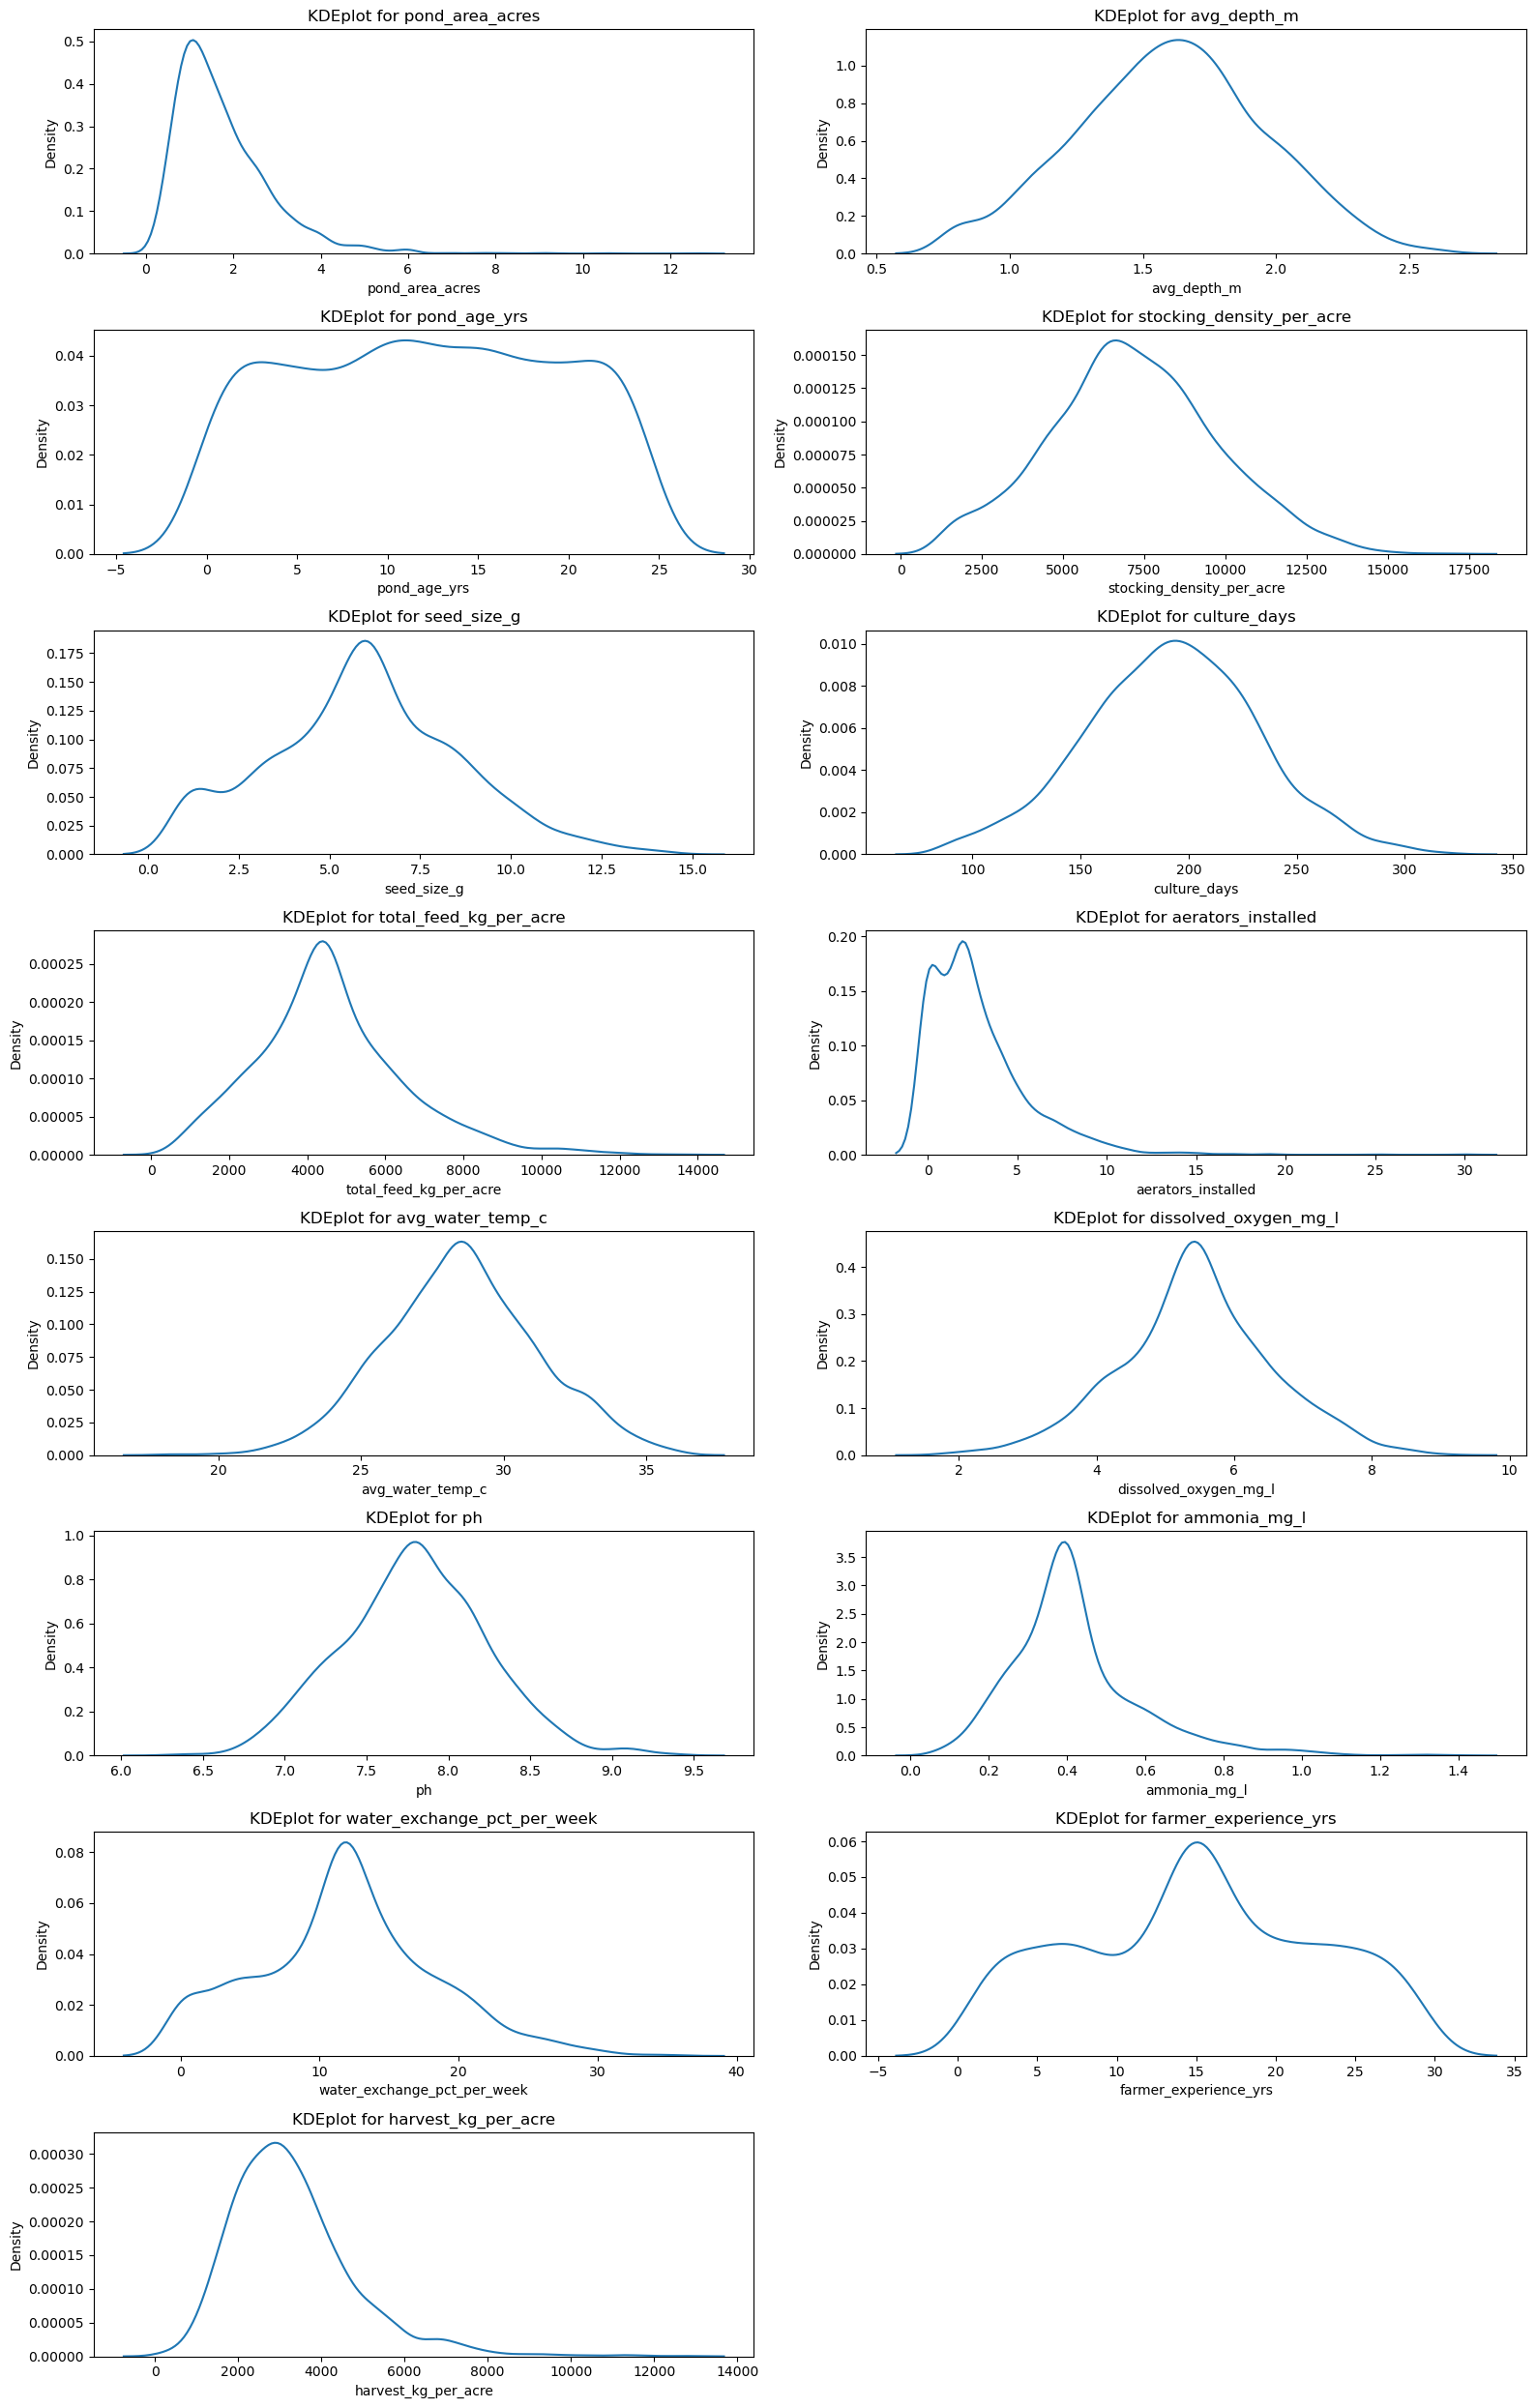

In [32]:
cols = num_cols

plt.figure(figsize=(16,25))
for i in range(len(cols)):
    plt.subplot(8,2,i+1)
    sns.kdeplot(x=df[cols[i]])
    plt.title(f'KDEplot for {cols[i]}')
plt.tight_layout()
plt.show()

Inference-
- Most water-quality and farm columns (avg_depth_m, avg_water_temp_c, culture_days, ph) are roughly bell-shaped.  
- pond_area_acres, aerators_installed, ammonia_mg_l and the target harvest_kg_per_acre are right-skewed with a long tail of high values 


### Bivariate analysis (categorical vs target)


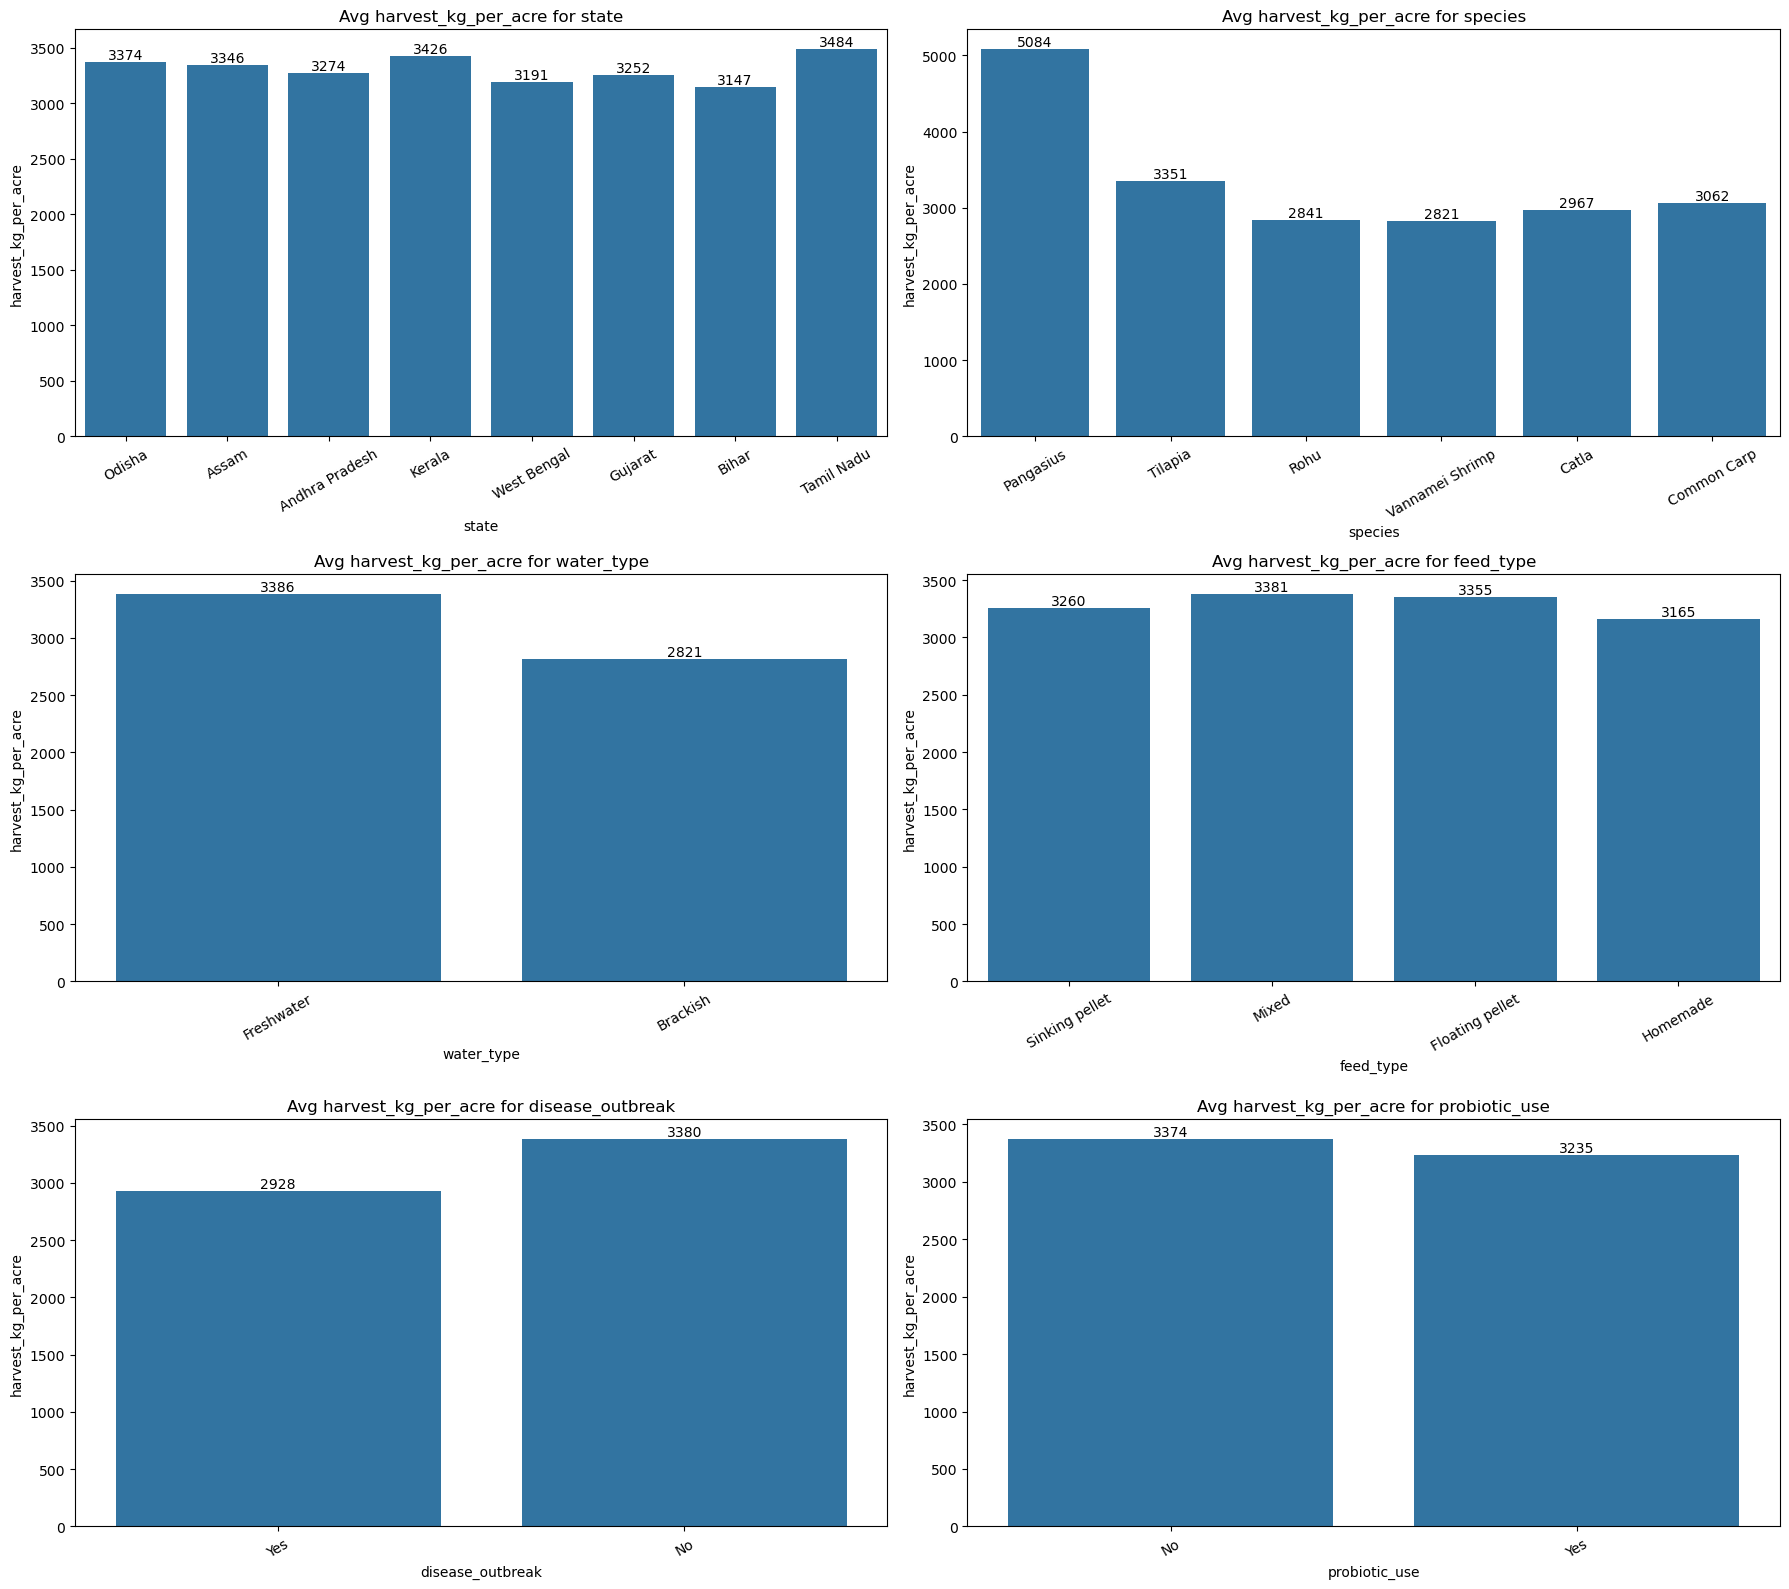

In [33]:
cols = cat_cols

plt.figure(figsize=(18,16))
for i in range(len(cols)):
    plt.subplot(3,2,i+1)
    ax= sns.barplot(x=df[cols[i]],y=df['harvest_kg_per_acre'],errorbar=('ci',0))
    ax.bar_label(ax.containers[0],fmt='%.0f')
    plt.xticks(rotation=30)
    plt.title(f'Avg harvest_kg_per_acre for {cols[i]}')
plt.tight_layout()
plt.show()

Inference-
- Species shows the biggest difference: Pangasius averages about 5,084 kg/acre, while the other species range from about 2,800 to 3,350.  
- Brackish ponds average about 2,821 against about 3,386 for freshwater, so this gap is really a species effect.  
- Ponds with a disease outbreak average about 2,928 compared with about 3,380 without one.  
- State and feed type show only small differences.  
- Probiotic users do not have higher harvest (about 3,235 vs 3,374 without).

### Bivariate analysis- countplot


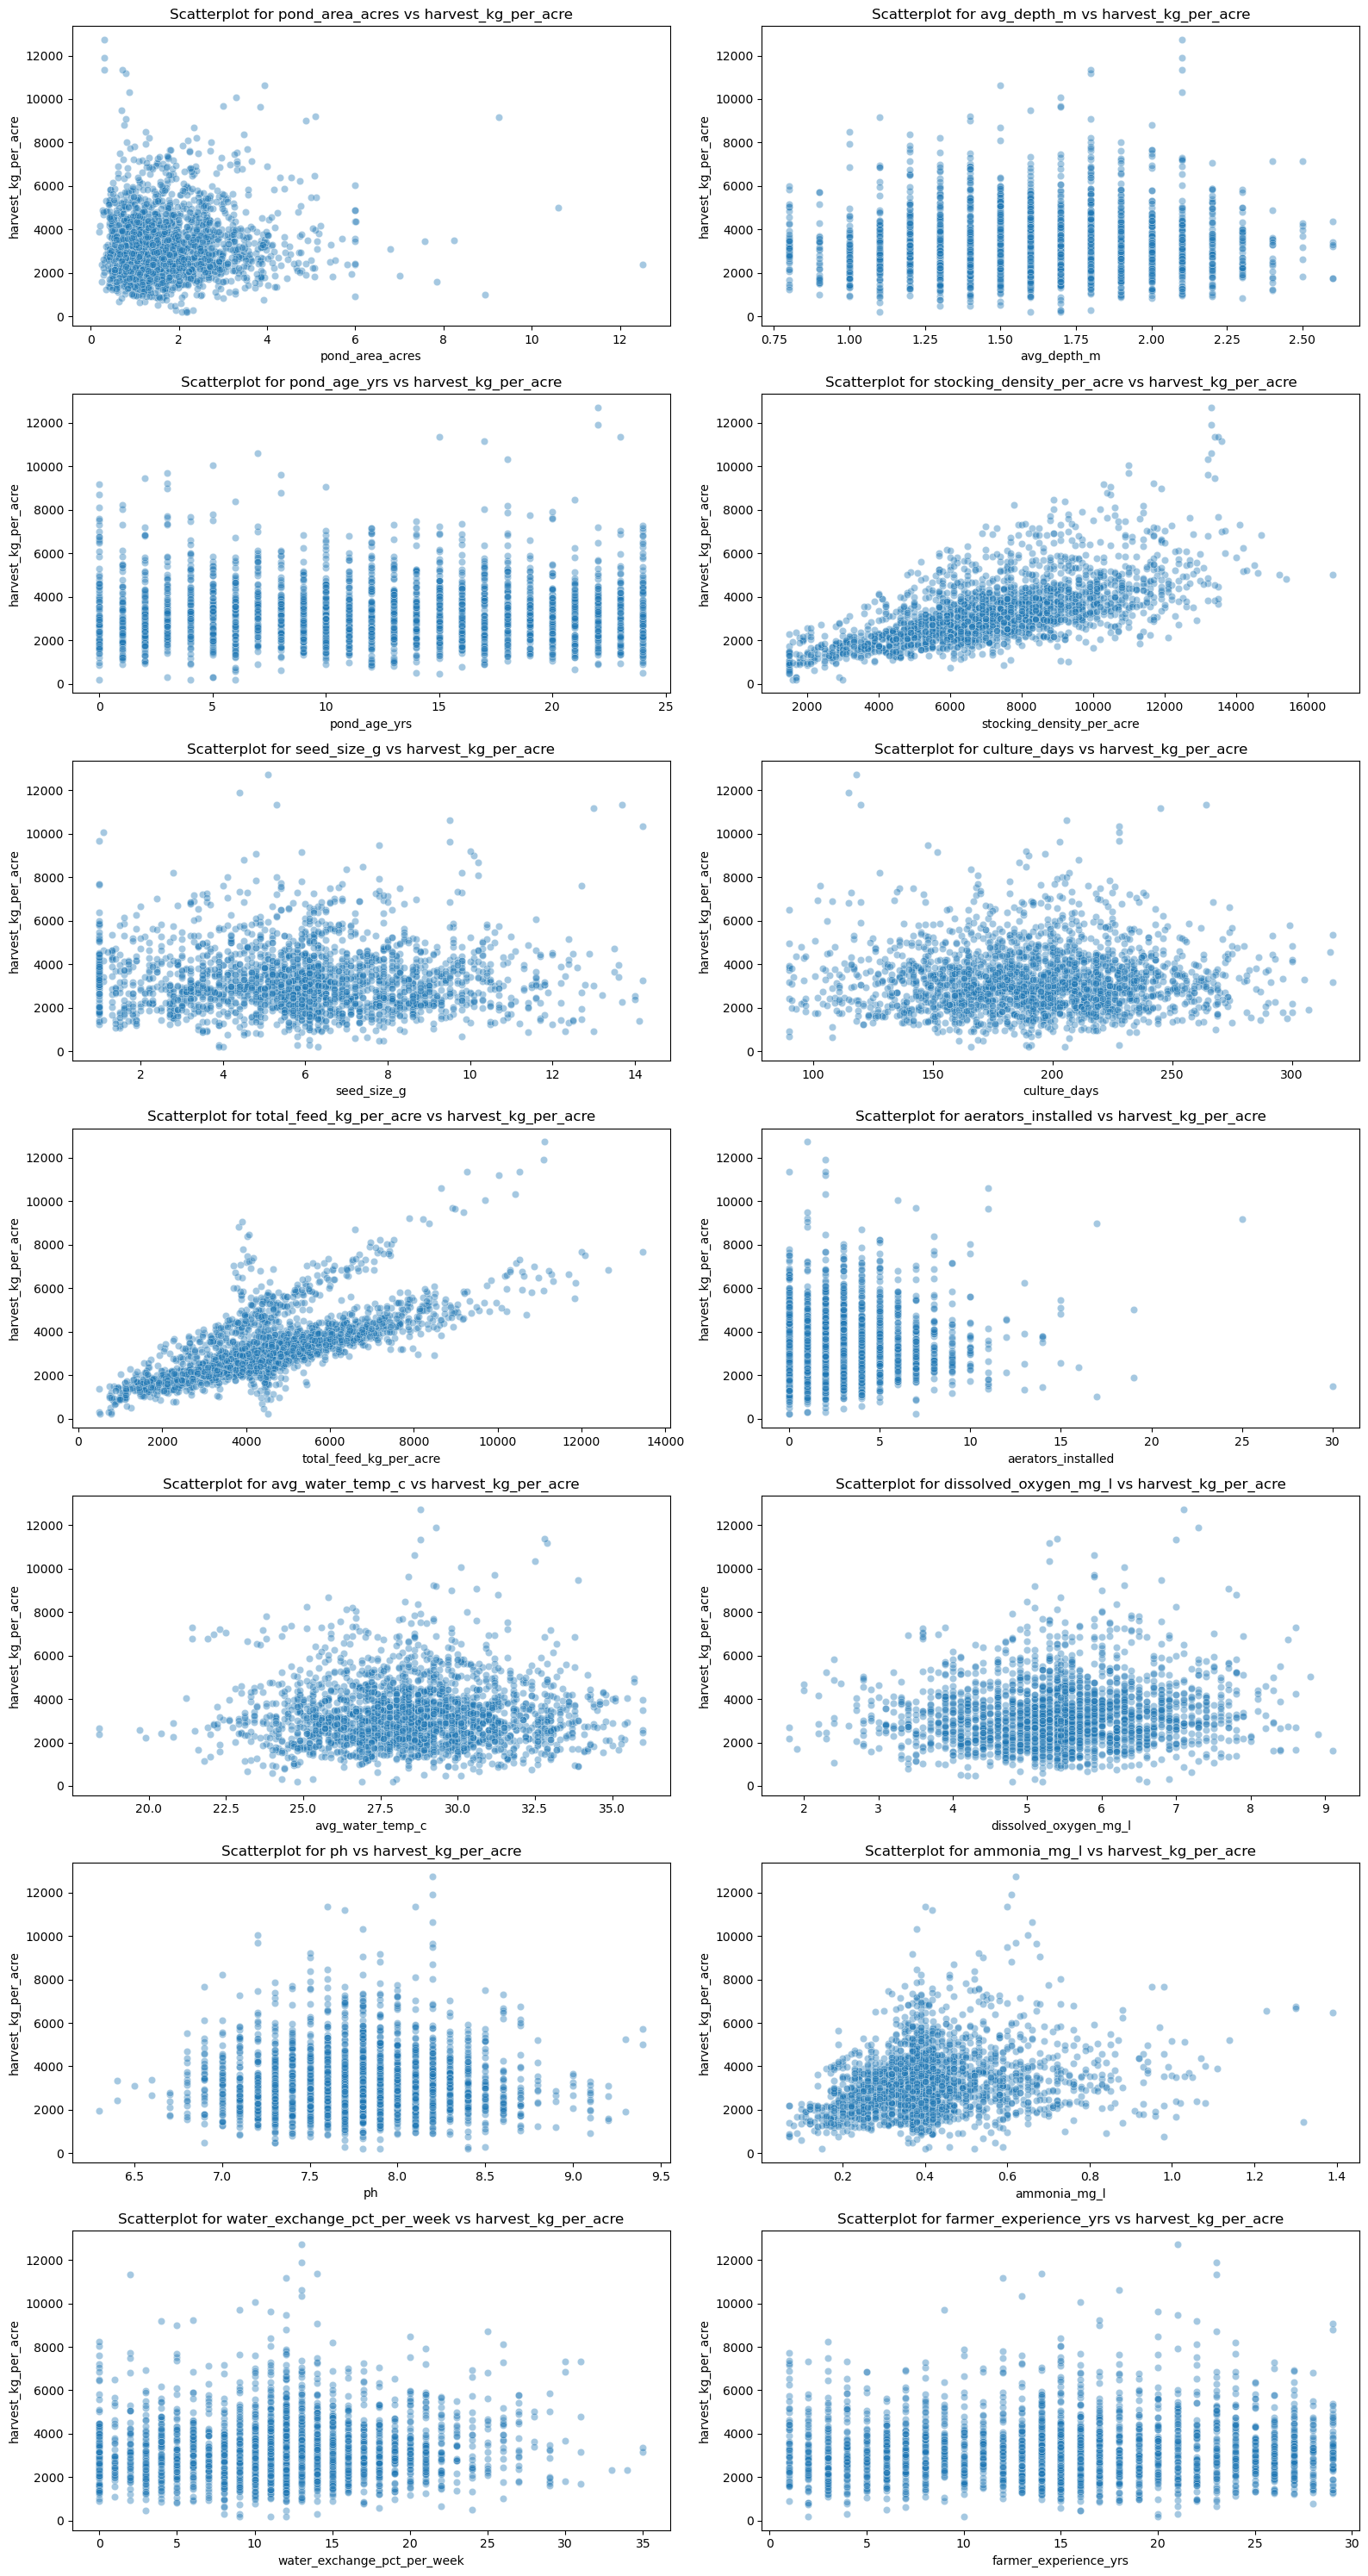

In [34]:
cols = num_cols[:-1]

plt.figure(figsize=(16,30))
for i in range(len(cols)):
    plt.subplot(7,2,i+1)
    sns.scatterplot(x=df[cols[i]],y=df['harvest_kg_per_acre'],alpha=0.4)
    plt.title(f'Scatterplot for {cols[i]} vs harvest_kg_per_acre')
plt.tight_layout()
plt.show()

Inference-
- total_feed_kg_per_acre and stocking_density_per_acre show a clear upward, roughly linear trend with harvest.  
- ammonia_mg_l shows a mild upward trend.  

### Correlation

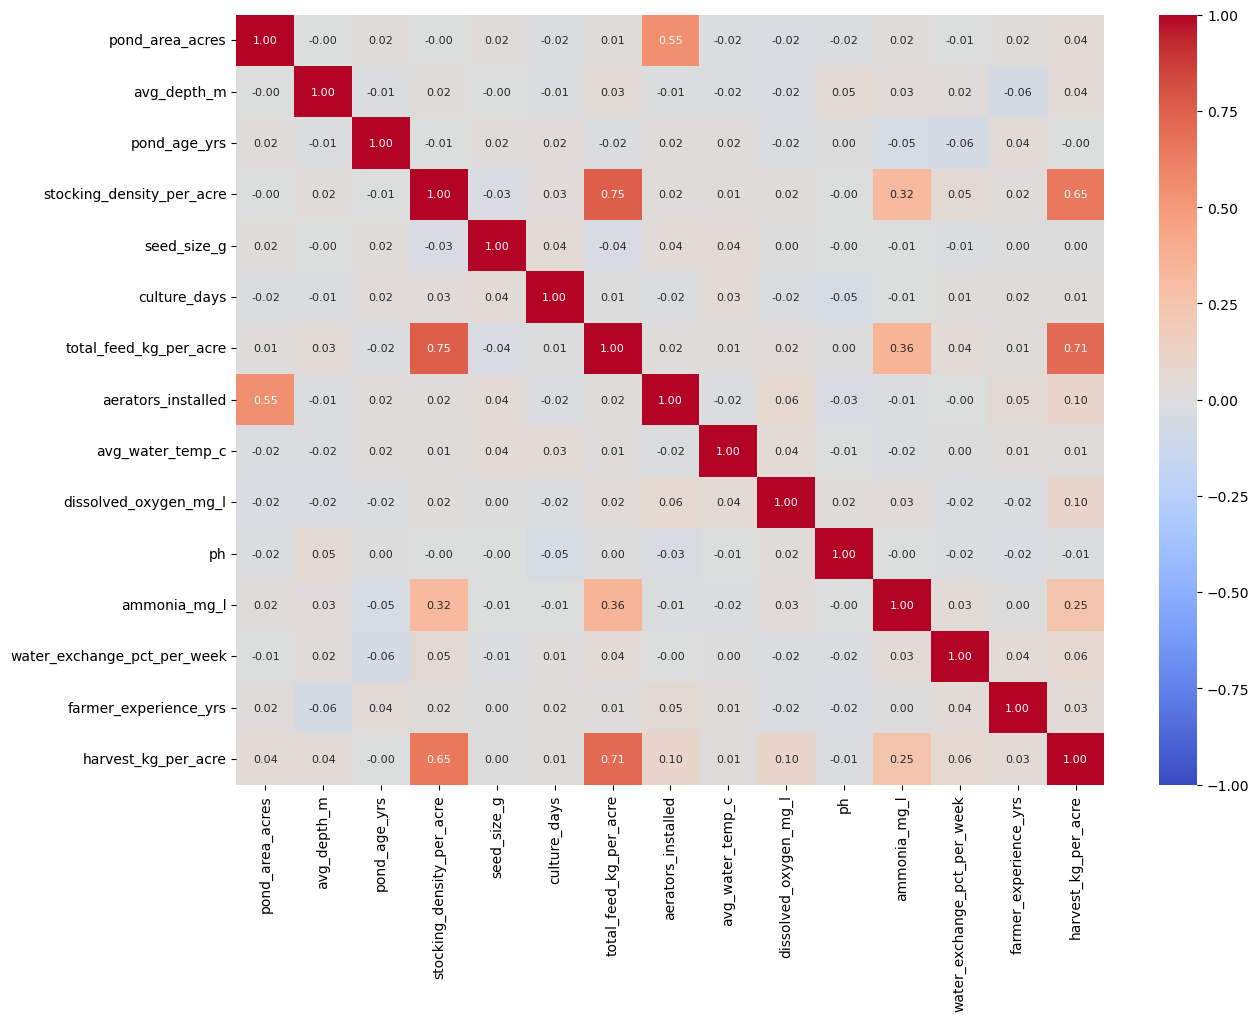

In [35]:
plt.figure(figsize=(14,10))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True,vmin=-1,vmax=1, cmap = 'coolwarm',fmt='.2f',annot_kws={'size':8})
plt.show()

Inference-
- Harvest is most strongly correlated with total_feed_kg_per_acre (about 0.71) and stocking_density_per_acre (about 0.65), then ammonia_mg_l (about 0.25).  
- Every other feature is below 0.11, so most of the signal comes from feed and stocking density. 

### Feature Engineering

In [36]:
print(cat_cols)
print(df.shape)

Index(['state', 'species', 'water_type', 'feed_type', 'disease_outbreak',
       'probiotic_use'],
      dtype='object')
(2300, 22)


In [37]:
print(df['state'].value_counts())
print(df['species'].value_counts())
print(df['water_type'].value_counts())
print(df['feed_type'].value_counts())
print(df['disease_outbreak'].value_counts())
print(df['probiotic_use'].value_counts())

state
Andhra Pradesh    681
West Bengal       377
Odisha            275
Tamil Nadu        237
Kerala            204
Assam             192
Bihar             169
Gujarat           165
Name: count, dtype: int64
species
Rohu               563
Catla              385
Tilapia            384
Vannamei Shrimp    341
Pangasius          339
Common Carp        288
Name: count, dtype: int64
water_type
Freshwater    1959
Brackish       341
Name: count, dtype: int64
feed_type
Floating pellet    909
Homemade           483
Mixed              471
Sinking pellet     437
Name: count, dtype: int64
disease_outbreak
No     1905
Yes     395
Name: count, dtype: int64
probiotic_use
Yes    1180
No     1120
Name: count, dtype: int64


### Drop the redundant column (water_type)

water_type is fully determined by species, all 341 Brackish ponds are Vannamei Shrimp, and every Freshwater pond is another species. If both are kept, the dummies water_type_Freshwater and species_Vannamei Shrimp become perfectly collinear (r = -1) and their coefficients become meaningless. So water_type is dropped before encoding. The test R² does not change.

In [38]:
cat_cols_model = cat_cols.drop('water_type')
df_dummies = pd.get_dummies(data=df.drop(columns='water_type'),columns=cat_cols_model,drop_first=True, dtype=int)
print(df_dummies.shape)
print(df_dummies.columns)

(2300, 33)
Index(['pond_id', 'pond_area_acres', 'avg_depth_m', 'pond_age_yrs',
       'stocking_density_per_acre', 'seed_size_g', 'culture_days',
       'total_feed_kg_per_acre', 'aerators_installed', 'avg_water_temp_c',
       'dissolved_oxygen_mg_l', 'ph', 'ammonia_mg_l',
       'water_exchange_pct_per_week', 'farmer_experience_yrs',
       'harvest_kg_per_acre', 'state_Assam', 'state_Bihar', 'state_Gujarat',
       'state_Kerala', 'state_Odisha', 'state_Tamil Nadu', 'state_West Bengal',
       'species_Common Carp', 'species_Pangasius', 'species_Rohu',
       'species_Tilapia', 'species_Vannamei Shrimp', 'feed_type_Homemade',
       'feed_type_Mixed', 'feed_type_Sinking pellet', 'disease_outbreak_Yes',
       'probiotic_use_Yes'],
      dtype='object')


In [39]:
df_dummies.dtypes

pond_id                         object
pond_area_acres                float64
avg_depth_m                    float64
pond_age_yrs                     int64
stocking_density_per_acre      float64
seed_size_g                    float64
culture_days                   float64
total_feed_kg_per_acre         float64
aerators_installed             float64
avg_water_temp_c               float64
dissolved_oxygen_mg_l          float64
ph                             float64
ammonia_mg_l                   float64
water_exchange_pct_per_week    float64
farmer_experience_yrs          float64
harvest_kg_per_acre            float64
state_Assam                      int64
state_Bihar                      int64
state_Gujarat                    int64
state_Kerala                     int64
state_Odisha                     int64
state_Tamil Nadu                 int64
state_West Bengal                int64
species_Common Carp              int64
species_Pangasius                int64
species_Rohu             

### Define features (X) and target (y)


In [40]:
x = df_dummies.drop(['harvest_kg_per_acre','pond_id'],axis=1)
y = df_dummies['harvest_kg_per_acre']
print(x.shape)
print(y.shape)

(2300, 31)
(2300,)


In [41]:
x.head()

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,...,species_Common Carp,species_Pangasius,species_Rohu,species_Tilapia,species_Vannamei Shrimp,feed_type_Homemade,feed_type_Mixed,feed_type_Sinking pellet,disease_outbreak_Yes,probiotic_use_Yes
0,1.93,1.1,10,9000.0,6.4,165.0,3846.0,6.0,27.9,8.1,...,0,1,0,0,0,0,0,1,1,0
1,3.31,1.3,5,8800.0,6.8,168.0,6697.0,8.0,28.8,6.1,...,0,1,0,0,0,0,1,0,0,1
2,0.59,0.9,19,5400.0,5.7,203.0,4040.0,1.0,27.2,6.5,...,0,0,0,1,0,0,0,0,0,1
3,0.44,1.8,18,9400.0,4.3,178.0,4535.0,1.0,30.3,4.8,...,0,0,0,1,0,0,1,0,0,0
4,4.15,1.3,11,5700.0,7.2,203.0,2708.0,6.0,29.7,5.4,...,0,0,1,0,0,0,0,0,1,1


In [42]:
y.head()

0    4413.0
1    7536.0
2    3116.0
3    5646.0
4    2243.0
Name: harvest_kg_per_acre, dtype: float64

## Baseline statistical model (OLS)

###  OLS regression summary (statsmodels)

In [43]:
import statsmodels.api as sm

In [44]:
# create copies of x1 and y1 
x1 = x.copy()
y1 = y.copy()

In [45]:
x1 = sm.add_constant(x1)     # added to generate intercept
ols_m1  = sm.OLS(y1,x1).fit()  # Train the OLS Model
ols_m1.summary()              # generate OLS Summary

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     harvest_kg_per_acre   R-squared:                       0.837
Model:                             OLS   Adj. R-squared:                  0.834
Method:                  Least Squares   F-statistic:                     374.8
Date:                 Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                         15:15:15   Log-Likelihood:                -17980.
No. Observations:                 2300   AIC:                         3.602e+04
Df Residuals:                     2268   BIC:                         3.621e+04
Df Model:                           31                                         
Covariance Type:             nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                        -986.6490    290.804     -3.393      0.001   -1556.918    -416.379
pond_area_acres               -22.0225     13.745     -1.602      0.109     -48.976       4.931
avg_depth_m                   106.3413     36.041      2.951      0.003      35.664     177.018
pond_age_yrs                   -2.4085      1.776     -1.356      0.175      -5.891       1.074
stocking_density_per_acre       0.1339      0.008     17.705      0.000       0.119       0.149
seed_size_g                     7.1335      4.844      1.473      0.141      -2.366      16.633
culture_days                    1.0822      0.322      3.360      0.001       0.451       1.714
total_feed_kg_per_acre          0.4379      0.010     41.778      0.000       0.417       0.458
aerators_installed             34.8022      5.527      6.297      0.000      23.964      45.641
avg_water_temp_c                3.5691      4.734      0.754      0.451      -5.714      12.852
dissolved_oxygen_mg_l          77.5160     11.520      6.729      0.000      54.925     100.107
ph                             -0.6664     28.502     -0.023      0.981     -56.559      55.227
ammonia_mg_l                 -156.7631     81.782     -1.917      0.055    -317.139       3.612
water_exchange_pct_per_week     4.4981      1.997      2.253      0.024       0.583       8.413
farmer_experience_yrs           2.6037      1.674      1.556      0.120      -0.679       5.886
state_Assam                    29.9381     49.748      0.602      0.547     -67.618     127.494
state_Bihar                  -117.3010     52.590     -2.230      0.026    -220.430     -14.172
state_Gujarat                 -66.3614     52.918     -1.254      0.210    -170.134      37.411
state_Kerala                   15.2134     48.935      0.311      0.756     -80.748     111.175
state_Odisha                  -27.1987     43.557     -0.624      0.532    -112.614      58.216
state_Tamil Nadu               29.0886     45.987      0.633      0.527     -61.093     119.270
state_West Bengal            -100.1864     39.127     -2.561      0.011    -176.915     -23.457
species_Common Carp           236.9233     47.695      4.967      0.000     143.392     330.454
species_Pangasius            2206.0235     45.574     48.405      0.000    2116.652    2295.395
species_Rohu                  -55.9301     40.597     -1.378      0.168    -135.541      23.681
species_Tilapia               374.9640     44.227      8.478      0.000     288.234     461.694
species_Vannamei Shrimp      -184.4232     45.667     -4.038      0.000    -273.976     -94.870
feed_type_Homemade            -16.1661     34.377     -0.470      0.638     -83.580      51.248
feed_type_Mixed                45.0284     34.748      1.296      0.195     -23.114     113.170


### Compare R2 and Adjusted R2

In [46]:
print('OLS_M1')
print('R2',ols_m1.rsquared)
print('Adj_R2',ols_m1.rsquared_adj)

OLS_M1
R2 0.8366853385878465
Adj_R2 0.8344530835156346


### Split data into train and test

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30, random_state=57)
print(x_train.shape,x_test.shape)
print(y_train.shape,y_test.shape)

(1610, 31) (690, 31)
(1610,) (690,)


### Baseline ML model (Linear Regression)

###  Train/test split + scikit-learn model

In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import * 

In [50]:
x_train.head()

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,...,species_Common Carp,species_Pangasius,species_Rohu,species_Tilapia,species_Vannamei Shrimp,feed_type_Homemade,feed_type_Mixed,feed_type_Sinking pellet,disease_outbreak_Yes,probiotic_use_Yes
1199,1.76,1.5,19,5300.0,5.3,205.0,3792.0,2.0,32.2,5.1,...,0,1,0,0,0,0,0,0,1,0
1748,1.64,1.5,12,7400.0,6.1,227.0,4479.0,5.0,30.5,7.7,...,1,0,0,0,0,0,0,0,0,1
2084,1.12,1.8,2,3300.0,7.1,230.0,2737.0,0.0,27.7,4.4,...,0,0,0,1,0,1,0,0,1,1
230,1.13,2.0,3,7900.0,1.0,191.0,6846.0,3.0,29.8,5.9,...,0,0,1,0,0,0,0,0,1,1
825,3.32,2.5,12,8300.0,7.8,203.0,5848.0,9.0,26.8,6.4,...,0,1,0,0,0,0,0,1,0,0


In [51]:
x_test.head()

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,...,species_Common Carp,species_Pangasius,species_Rohu,species_Tilapia,species_Vannamei Shrimp,feed_type_Homemade,feed_type_Mixed,feed_type_Sinking pellet,disease_outbreak_Yes,probiotic_use_Yes
118,1.59,1.5,20,8100.0,8.1,231.0,6254.0,5.0,34.7,6.0,...,1,0,0,0,0,0,0,0,0,1
468,0.69,1.5,5,9300.0,5.0,211.0,4627.0,1.0,30.4,5.4,...,0,0,0,1,0,0,1,0,0,0
1296,0.66,1.7,23,11100.0,1.0,143.0,5716.0,1.0,27.5,6.3,...,1,0,0,0,0,0,0,0,0,1
564,0.72,1.7,9,6200.0,7.6,202.0,3276.0,2.0,27.2,6.0,...,0,0,1,0,0,0,0,1,1,1
1061,3.04,1.6,2,8000.0,4.6,220.0,4517.0,4.0,30.0,5.0,...,0,0,1,0,0,1,0,0,0,1


In [52]:
y_test.head()

118     4297.0
468     5612.0
1296    3915.0
564     2116.0
1061    3189.0
Name: harvest_kg_per_acre, dtype: float64

In [53]:
def eval_model(ytest,ypred):
    mae= mean_absolute_error(ytest,ypred)
    mse= mean_squared_error(ytest,ypred)
    rmse= np.sqrt(mse)
    r2= r2_score(ytest,ypred)
    print('MAE',mae,'MSE',mse,'RMSE',rmse)
    print('Test_R2',r2)
    

###  Train the baseline Linear Regression model

In [54]:
lr1 = LinearRegression()    # Create an instance of Linear Regreisson
lr1.fit(x_train,y_train)    # Train model on x_train and y_train

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [55]:
ypred_lr1 = lr1.predict(x_test)  
eval_model(y_test,ypred_lr1)

MAE 432.01625457403395 MSE 364677.7937576198 RMSE 603.8855800212651
Test_R2 0.8222171467271566


### overfitting check

In [56]:
print('Train Score',lr1.score(x_train,y_train))   # Train R2_Score
print('Test Score',lr1.score(x_test,y_test))      # Test R2_Score

Train Score 0.8411278482112217
Test Score 0.8222171467271566


In [57]:
m_lr = lr1.coef_
c_lr = lr1.intercept_
print('Coef',m_lr)
print('Intercept',c_lr)

Coef [-2.59265064e+01  1.24676219e+02 -2.60593873e+00  1.38193404e-01
  1.75050572e+00  1.19349211e+00  4.35488041e-01  3.49798610e+01
  3.99335675e+00  7.47474629e+01  3.10934477e+00 -1.30117415e+02
  4.57169304e+00  4.41715577e+00  4.30014545e+01 -1.30084818e+02
 -7.22219582e+01  1.09556162e+01 -1.95278566e+01  5.51849211e+01
 -8.66221413e+01  2.27029636e+02  2.22024562e+03 -7.46863408e+01
  3.54257237e+02 -2.39405910e+02 -2.28438887e+01  6.33830843e+01
 -3.94508511e+01 -3.51775451e+02  7.22380782e+01]
Intercept -1068.807707058308


In [58]:
feat_coef = pd.DataFrame({'Features':x_train.columns,'Coef':m_lr})
feat_coef

,Features,Coef
0,pond_area_acres,-25.926506
1,avg_depth_m,124.676219
2,pond_age_yrs,-2.605939
3,stocking_density_per_acre,0.138193
4,seed_size_g,1.750506
5,culture_days,1.193492
6,total_feed_kg_per_acre,0.435488
7,aerators_installed,34.979861
8,avg_water_temp_c,3.993357
9,dissolved_oxygen_mg_l,74.747463


### Regression assumption checks 

### 1) Linearity check 

In [59]:
numeric_cols = ['pond_area_acres', 'avg_depth_m', 'pond_age_yrs',
       'stocking_density_per_acre', 'seed_size_g', 'culture_days',
       'total_feed_kg_per_acre', 'aerators_installed', 'avg_water_temp_c',
       'dissolved_oxygen_mg_l', 'ph', 'ammonia_mg_l',
       'water_exchange_pct_per_week', 'farmer_experience_yrs',
       'harvest_kg_per_acre']

corr_with_harvest_kg_per_acre = (df[numeric_cols] .corr()['harvest_kg_per_acre'].drop('harvest_kg_per_acre') .sort_values(ascending=False))

corr_with_harvest_kg_per_acre

total_feed_kg_per_acre         0.709362
stocking_density_per_acre      0.653992
ammonia_mg_l                   0.248986
aerators_installed             0.098512
dissolved_oxygen_mg_l          0.096106
water_exchange_pct_per_week    0.064640
pond_area_acres                0.042936
avg_depth_m                    0.035209
farmer_experience_yrs          0.034778
avg_water_temp_c               0.014895
culture_days                   0.012769
seed_size_g                    0.000093
pond_age_yrs                  -0.004607
ph                            -0.010021
Name: harvest_kg_per_acre, dtype: float64

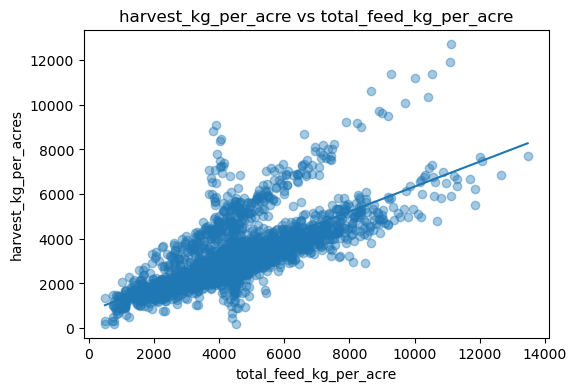

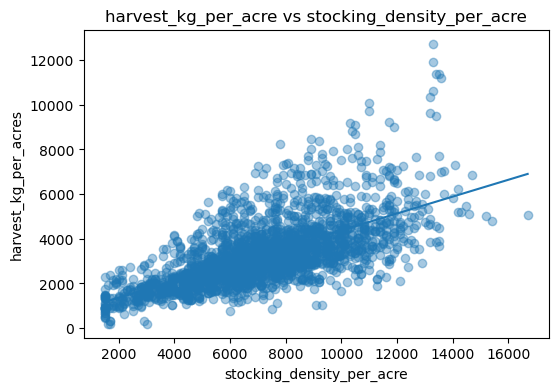

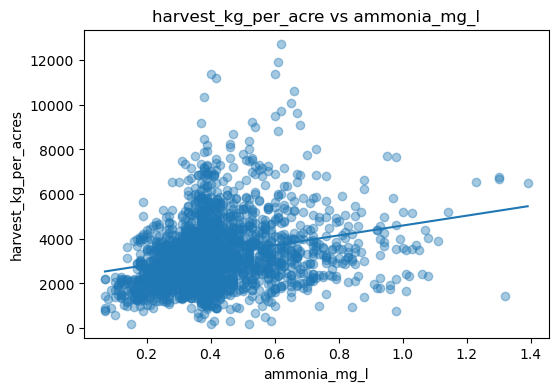

In [60]:
top_features = list(corr_with_harvest_kg_per_acre.index[:3])

for col in top_features:
    plt.figure(figsize=(6,4))
    plt.scatter(df[col], df['harvest_kg_per_acre'], alpha=0.4)

    m, b = np.polyfit(df[col], df['harvest_kg_per_acre'], 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    plt.plot(x_line, m*x_line + b)

    plt.title(f"harvest_kg_per_acre vs {col}")
    plt.xlabel(col)
    plt.ylabel("harvest_kg_per_acres")
    plt.show()

Inference-  
- total_feed_kg_per_acre (r ≈ 0.71) and stocking_density_per_acre (r ≈ 0.65) have a clear positive, roughly linear relationship with harvest, so a linear model is reasonable.  
- ammonia_mg_l (r ≈ 0.25) has a much weaker link.  
- Some curvature/interaction may still remain, which is why we also check the residuals below.

### 2. Multicollinearity check (VIF)


In [61]:
df

,pond_id,state,species,water_type,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,...,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,ph,ammonia_mg_l,water_exchange_pct_per_week,disease_outbreak,probiotic_use,farmer_experience_yrs,harvest_kg_per_acre
0,PND11915,Odisha,Pangasius,Freshwater,1.93,1.1,10,9000.0,6.4,165.0,...,6.0,27.9,8.1,8.0,0.21,10.0,Yes,No,27.0,4413.0
1,PND10924,Odisha,Pangasius,Freshwater,3.31,1.3,5,8800.0,6.8,168.0,...,8.0,28.8,6.1,7.5,0.53,5.0,No,Yes,22.0,7536.0
2,PND10873,Assam,Tilapia,Freshwater,0.59,0.9,19,5400.0,5.7,203.0,...,1.0,27.2,6.5,8.1,0.49,12.0,No,Yes,29.0,3116.0
3,PND10410,Andhra Pradesh,Tilapia,Freshwater,0.44,1.8,18,9400.0,4.3,178.0,...,1.0,30.3,4.8,8.0,0.41,13.0,No,No,18.0,5646.0
4,PND10369,Kerala,Rohu,Freshwater,4.15,1.3,11,5700.0,7.2,203.0,...,6.0,29.7,5.4,7.8,0.37,22.0,Yes,Yes,27.0,2243.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2295,PND11697,Andhra Pradesh,Catla,Freshwater,1.07,1.9,6,8900.0,10.2,202.0,...,2.0,31.2,6.3,7.6,0.28,24.0,No,Yes,13.0,4647.0
2296,PND10300,Andhra Pradesh,Catla,Freshwater,1.85,1.9,17,4500.0,7.8,185.0,...,3.0,28.6,4.3,7.3,0.26,25.0,No,No,4.0,2101.0
2297,PND10042,Odisha,Rohu,Freshwater,1.39,1.7,7,8500.0,5.8,194.0,...,2.0,32.8,6.8,7.6,0.32,11.0,No,Yes,16.0,4228.0
2298,PND11071,Bihar,Rohu,Freshwater,1.11,1.7,1,5500.0,4.4,192.0,...,3.0,35.3,6.7,6.3,0.38,3.0,No,No,13.0,1941.0


In [62]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif_const = sm.add_constant(x_train)      # VIF must be computed WITH the constant
vif_df = pd.DataFrame()
vif_df['Feature'] = X_vif_const.columns
vif_df['VIF'] = [variance_inflation_factor(X_vif_const.values, i) for i in range(X_vif_const.shape[1])]
vif_df = vif_df[vif_df['Feature']!='const']

# Show the top VIF values (higher first)
vif_df.sort_values('VIF', ascending=False).head(15)

,Feature,VIF
7,total_feed_kg_per_acre,2.407243
4,stocking_density_per_acre,2.351476
24,species_Rohu,1.950716
25,species_Tilapia,1.797195
23,species_Pangasius,1.695715
26,species_Vannamei Shrimp,1.690682
22,species_Common Carp,1.589093
8,aerators_installed,1.506910
1,pond_area_acres,1.489597
21,state_West Bengal,1.311974


Inference-  
- After removing the redundant water_type, every VIF is below 2.5. Multicollinearity is not a concern (VIF < 5).  
- Before the fix, water_type_Freshwater and species_Vannamei Shrimp were perfectly collinear which is why water_type was dropped.

### 3. Homoscedasticity check (residuals vs predicted)

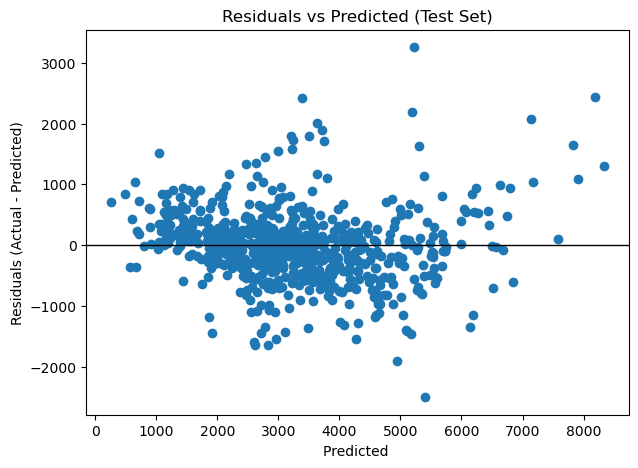

In [63]:
import matplotlib.pyplot as plt

# Predict sales on the test set
ypred_lr1 = lr1.predict(x_test)

# Calculate residuals
residuals = y_test - ypred_lr1

# Plot residuals vs predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(ypred_lr1, residuals)
plt.axhline(0, color='black', linewidth=1)



plt.title('Residuals vs Predicted (Test Set)')
plt.xlabel('Predicted ')
plt.ylabel('Residuals (Actual - Predicted)')

plt.show()

In [64]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
 
# Fit OLS on training data for diagnostics
X_train_sm = sm.add_constant(x_train)
ols_train = sm.OLS(y_train, X_train_sm).fit()
 
# Breusch–Pagan test
bp_stat, bp_pvalue, f_stat, f_pvalue = het_breuschpagan(ols_train.resid, ols_train.model.exog)
print("Breusch–Pagan p-value:", bp_pvalue)
 
# Durbin–Watson (extra diagnostic)
dw = durbin_watson(ols_train.resid)
print("Durbin–Watson:", dw)
 

Breusch–Pagan p-value: 4.794986469157381e-41
Durbin–Watson: 1.998154933214983


Inference-
- Breusch–Pagan p-value ≈ 5e-41 (far below 0.05) → strong evidence of heteroscedasticity: the error spread is not constant (about 400 kg for the lowest quarter of predictions vs about 750 kg for the highest).
- Predictions and coefficients are still usable, but p-values and confidence intervals are less reliable (robust standard errors such as HC3 can be used).
- Durbin–Watson ≈ 2.0 → no autocorrelation.

### 4. Normality of residuals 

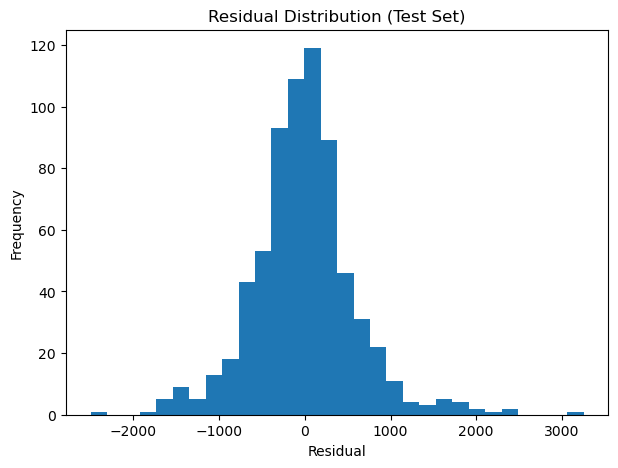

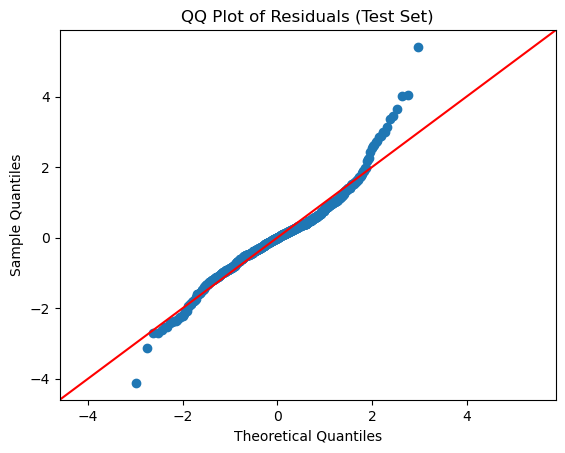

In [65]:
plt.figure(figsize=(7,5))
plt.hist(residuals, bins=30)
plt.title('Residual Distribution (Test Set)')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()
 
import scipy.stats as stats
sm.qqplot(residuals, line='45', fit=True)
plt.title('QQ Plot of Residuals (Test Set)')
plt.show()

Inference-  
- Residuals are centred near zero but heavy-tailed so they are not perfectly normal. This comes mostly from a few large errors on high-yield ponds.  
- With 1,610 training rows, the predictions and coefficients are still reliable, but treat p-values and confidence intervals with some caution.

### Regularized Regression

In [66]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [67]:
# Scale features (fit scaler only on training set)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
 
# Convert back to DataFrame to keep column names (helps interpretation)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)
 

In [68]:
x_train_scaled

,pond_area_acres,avg_depth_m,pond_age_yrs,stocking_density_per_acre,seed_size_g,culture_days,total_feed_kg_per_acre,aerators_installed,avg_water_temp_c,dissolved_oxygen_mg_l,...,species_Common Carp,species_Pangasius,species_Rohu,species_Tilapia,species_Vannamei Shrimp,feed_type_Homemade,feed_type_Mixed,feed_type_Sinking pellet,disease_outbreak_Yes,probiotic_use_Yes
1199,-0.009718,-0.278855,0.961173,-0.723454,-0.251711,0.319156,-0.419976,-0.283868,1.356780,-0.322255,...,-0.374468,2.332381,-0.555826,-0.465759,-0.414441,-0.520306,-0.513553,-0.478547,2.188919,-1.023888
1748,-0.115377,-0.278855,-0.008692,0.087607,0.052791,0.878452,-0.055936,0.779811,0.732073,2.037484,...,2.670452,-0.428746,-0.555826,-0.465759,-0.414441,-0.520306,-0.513553,-0.478547,-0.456846,0.976670
2084,-0.573233,0.558230,-1.394213,-1.495893,0.433419,0.954720,-0.979019,-0.992987,-0.296855,-0.957569,...,-0.374468,-0.428746,-0.555826,2.147034,-0.414441,1.921946,-0.513553,-0.478547,2.188919,0.976670
230,-0.564428,1.116286,-1.255661,0.280717,-1.888410,-0.036760,1.198332,0.070692,0.474841,0.403819,...,-0.374468,-0.428746,1.799123,-0.465759,-0.414441,-0.520306,-0.513553,-0.478547,2.188919,0.976670
825,1.363848,2.511428,-0.008692,0.435205,0.699859,0.268311,0.669494,2.198049,-0.627582,0.857615,...,-0.374468,2.332381,-0.555826,-0.465759,-0.414441,-0.520306,-0.513553,2.089657,-0.456846,-1.023888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
984,1.548751,-1.394968,-1.671317,-0.221369,-0.442025,-0.189296,0.039445,1.843490,-2.428207,-0.413014,...,-0.374468,-0.428746,1.799123,-0.465759,-0.414441,-0.520306,1.947220,-0.478547,-0.456846,0.976670
1675,-0.185816,0.000173,-0.701452,-2.191088,-0.936841,1.005565,-1.842223,-0.283868,0.254356,-0.049977,...,-0.374468,-0.428746,-0.555826,-0.465759,2.412889,-0.520306,1.947220,-0.478547,-0.456846,0.976670
421,-0.661282,0.279202,-0.701452,2.018705,-1.203280,0.776762,0.308633,-0.992987,0.585083,-0.413014,...,-0.374468,2.332381,-0.555826,-0.465759,-0.414441,-0.520306,-0.513553,2.089657,-0.456846,0.976670
1122,-1.092723,-0.278855,-1.117108,1.864217,0.623733,2.454652,1.061089,-0.283868,-0.260108,0.040782,...,-0.374468,-0.428746,1.799123,-0.465759,-0.414441,-0.520306,-0.513553,-0.478547,-0.456846,0.976670



### Train Ridge, Lasso, ElasticNet (no cross-validation yet)

In [69]:
# Helper to store metrics in a clean table
def get_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }
 
results_initial = []

In [70]:
pred_baseline = lr1.predict(x_test)
baseline_metrics = get_metrics(y_test, pred_baseline)
baseline_metrics['Model'] = 'Baseline LinearRegression (Part 1)'
results_initial.append(baseline_metrics)

### Ridge (L2)

In [71]:
ridge_basic = Ridge(alpha=1.0)
ridge_basic.fit(x_train_scaled, y_train)
pred_ridge = ridge_basic.predict(x_test_scaled)
m_ridge = get_metrics(y_test, pred_ridge)
m_ridge['Model'] = 'Ridge (alpha=1.0)'
results_initial.append(m_ridge)

### Lasso (L1) 

In [72]:
lasso_basic = Lasso(alpha=0.01, max_iter=10000)
lasso_basic.fit(x_train_scaled, y_train)
pred_lasso = lasso_basic.predict(x_test_scaled)
m_lasso = get_metrics(y_test, pred_lasso)
m_lasso['Model'] = 'Lasso (alpha=0.01)'
results_initial.append(m_lasso)

### ElasticNet (L1 + L2)

In [73]:
enet_basic = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)
enet_basic.fit(x_train_scaled, y_train)
pred_enet = enet_basic.predict(x_test_scaled)
m_enet = get_metrics(y_test, pred_enet)
m_enet['Model'] = 'ElasticNet (alpha=0.01, l1_ratio=0.5)'
results_initial.append(m_enet)



In [74]:
results_initial_df=pd.DataFrame(results_initial).sort_values('RMSE')
results_initial_df

,MAE,RMSE,R2,Model
3,431.915022,603.775696,0.822282,"ElasticNet (alpha=0.01, l1_ratio=0.5)"
1,431.998829,603.867920,0.822228,Ridge (alpha=1.0)
2,432.013308,603.884140,0.822218,Lasso (alpha=0.01)
0,432.016255,603.885580,0.822217,Baseline LinearRegression (Part 1)


### K-Fold cross-validation

In [75]:
def kfold_score(model_class, model_params, X, y, k=5, random_state=57):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    rmse_scores = []
    r2_scores = []

    for tr_idx, val_idx in kf.split(X):
        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]
        y_tr = y.iloc[tr_idx]
        y_val = y.iloc[val_idx]

        model = model_class(**model_params)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, pred))
        r2 = r2_score(y_val, pred)

        rmse_scores.append(rmse)
        r2_scores.append(r2)

    return {
        'RMSE_Mean': np.mean(rmse_scores),
        'RMSE_Std': np.std(rmse_scores),
        'R2_Mean': np.mean(r2_scores),
        'R2_Std': np.std(r2_scores)
    }


### Tune Ridge (alpha) with K-Fold

In [76]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_cv_results = []
for a in ridge_alphas:
    res = kfold_score(Ridge, {'alpha': a}, x_train_scaled, y_train)
    res['Model'] = 'Ridge'
    res['alpha'] = a
    ridge_cv_results.append(res)

ridge_cv_df = pd.DataFrame(ridge_cv_results).sort_values('RMSE_Mean')
ridge_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
3,612.966183,33.211403,0.833020,0.014312,Ridge,10.00
2,612.977695,33.033211,0.832992,0.014540,Ridge,1.00
1,612.989036,33.016549,0.832983,0.014565,Ridge,0.10
0,612.990276,33.014895,0.832982,0.014568,Ridge,0.01
4,619.766082,35.511879,0.829452,0.013207,Ridge,100.00
5,794.427572,52.102907,0.720539,0.013280,Ridge,1000.00


### Tune Lasso (alpha) with K-Fold

In [83]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]

lasso_cv_results = []
for a in lasso_alphas:
    res = kfold_score(Lasso, {'alpha': a, 'max_iter': 10000}, x_train_scaled, y_train)
    res['Model'] = 'Lasso'
    res['alpha'] = a
    lasso_cv_results.append(res)

lasso_cv_df = pd.DataFrame(lasso_cv_results).sort_values('RMSE_Mean')
lasso_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
4,612.830322,33.081369,0.833078,0.014474,Lasso,1.0000
3,612.970456,33.020757,0.832994,0.014557,Lasso,0.1000
2,612.988613,33.015312,0.832983,0.014567,Lasso,0.0100
1,612.990236,33.014773,0.832982,0.014568,Lasso,0.0010
0,612.990398,33.014718,0.832982,0.014568,Lasso,0.0001


### Tune ElasticNet (alpha and l1_ratio) with K-Fold

In [82]:
enet_alphas = [0.001, 0.01, 0.1, 1, 10]
enet_l1_ratios = [0.1, 0.5, 0.9]

enet_cv_results = []
for a in enet_alphas:
    for l1 in enet_l1_ratios:
        res = kfold_score(ElasticNet, {'alpha': a, 'l1_ratio': l1, 'max_iter': 10000}, x_train_scaled, y_train)
        res['Model'] = 'ElasticNet'
        res['alpha'] = a
        res['l1_ratio'] = l1
        enet_cv_results.append(res)

enet_cv_df = pd.DataFrame(enet_cv_results).sort_values('RMSE_Mean')
enet_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha,l1_ratio
4,612.948389,33.138899,0.833021,0.014397,ElasticNet,0.010,0.5
5,612.972722,33.039183,0.832995,0.014531,ElasticNet,0.010,0.9
0,612.975870,33.036189,0.832993,0.014536,ElasticNet,0.001,0.1
1,612.981851,33.026626,0.832988,0.014550,ElasticNet,0.001,0.5
3,612.982318,33.244944,0.833015,0.014275,ElasticNet,0.010,0.1
2,612.988481,33.017133,0.832984,0.014564,ElasticNet,0.001,0.9
8,612.989978,33.277053,0.833015,0.014237,ElasticNet,0.100,0.9
7,615.919170,34.556067,0.831512,0.013465,ElasticNet,0.100,0.5
6,621.822462,35.946311,0.828339,0.013133,ElasticNet,0.100,0.1
11,623.791687,36.480885,0.827270,0.013095,ElasticNet,1.000,0.9


### Compare the best configuration from each model

In [79]:
best_ridge = ridge_cv_df.iloc[0]
best_lasso = lasso_cv_df.iloc[0]
best_enet = enet_cv_df.iloc[0]

compare_cv = pd.DataFrame([best_ridge, best_lasso, best_enet])
# print(best_ridge)
# print(best_lasso)
# print(best_enet)
compare_cv[['Model','alpha','l1_ratio','RMSE_Mean','RMSE_Std','R2_Mean','R2_Std']]

,Model,alpha,l1_ratio,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std
3,Ridge,10.00,NaN,612.966183,33.211403,0.833020,0.014312
4,Lasso,1.00,NaN,612.830322,33.081369,0.833078,0.014474
4,ElasticNet,0.01,0.5,612.948389,33.138899,0.833021,0.014397


In [80]:
results_list = []

# Baseline again (for easy comparison in one table)
results_list.append({
    'Model': 'Baseline LinearRegression (Part 1)',
    **get_metrics(y_test, lr1.predict(x_test))
})

# Tuned regularized models (scaled features)
ridge_final = Ridge(alpha=float(best_ridge['alpha']))
lasso_final = Lasso(alpha=float(best_lasso['alpha']), max_iter=10000)
enet_final = ElasticNet(alpha=float(best_enet['alpha']), l1_ratio=float(best_enet['l1_ratio']), max_iter=10000)

for name, model in [('Ridge (tuned)', ridge_final), ('Lasso (tuned)', lasso_final), ('ElasticNet (tuned)', enet_final)]:
    model.fit(x_train_scaled, y_train)
    pred = model.predict(x_test_scaled)
    results_list.append({
        'Model': name,
        **get_metrics(y_test, pred)
    })

results_df = pd.DataFrame(results_list).sort_values('RMSE')
results_df


,Model,MAE,RMSE,R2
1,Ridge (tuned),431.908288,603.760742,0.822291
2,Lasso (tuned),431.749024,603.770390,0.822285
3,ElasticNet (tuned),431.915022,603.775696,0.822282
0,Baseline LinearRegression (Part 1),432.016255,603.885580,0.822217


In [81]:
best_candidates = {
    'Ridge': float(best_ridge['RMSE_Mean']),
    'Lasso': float(best_lasso['RMSE_Mean']),
    'ElasticNet': float(best_enet['RMSE_Mean'])
}
winner = min(best_candidates, key=best_candidates.get)
winner


'Lasso'

### Conclusion



We cleaned the aquaculture dataset (2 duplicate rows removed, missing values in 3 columns filled), explored it, and built a Linear Regression model to predict harvest per acre (kg), then compared it with Ridge, Lasso and ElasticNet.

Model performance
- The baseline Linear Regression reaches a test R² of 0.82, RMSE ≈ 604 kg/acre (about 18% of the mean harvest of 3,302) and MAE ≈ 432 kg/acre (about 13%).
- Train R² (0.84) is close to test R² (0.82), and 5-fold CV R² is about 0.83 ± 0.014, so the model generalises well and does not overfit.

What drives harvest
- Feed per acre and stocking density are the strongest drivers (correlations 0.71 and 0.65). Every extra 1,000 kg of feed per acre adds about 435 kg of harvest, and every extra 1,000 seeds per acre adds about 138 kg, other factors held equal.
- Species matters: Pangasius yields about 2,200 kg/acre more than Catla, Tilapia and Common Carp slightly more, and Rohu and Vannamei Shrimp slightly less.
- A disease outbreak lowers harvest by about 350 kg/acre.
- Dissolved oxygen,aerators and probiotic use have small positive effects.
- pH, water temperature, seed size, pond age, pond area and farmer experience have no significant effect.
- Ammonia is positively correlated with harvest (0.25), but once feed is controlled for it is not significant (p ≈ 0.055) and its coefficient turns negative. The raw link most likely reflects heavier feeding rather than ammonia helping yield.

Regularization
- Ridge, Lasso and ElasticNet performed the same as plain Linear Regression (test R² ≈ 0.822). The model is not overfitting and multicollinearity is low (all VIF < 2.5 after removing the redundant water_type), so regularization gives no real gain.
